# Team Member Names
- Aneri Shah
- Devanshi Patel
- Nathan Palomera
- Ranya El-Shinawy

## Task A: Image analytics and LLM stories

For each selected campaign image, obtain (i) image labels (text) from Google Cloud Vision or an equivalent service, and (ii) a short, factual "story" (approximately 60–100 words) describing the image using a multimodal LLM API. Do not invent circumstances, diagnoses, identities, or events not visible in the photograph. Keep image_labels and LLM_stories in separate columns; retain the original campaign description as a third text field. State which services/models you used and provide the image-description prompt.

### Overview
We used the MDCC archive (`raw_data.csv` for campaign metadata, `Photos.zip` for images) and selected about 1,000 **Medical** campaigns. For each campaign's main image we got (i) labels from **Google Cloud Vision** and (ii) a short factual description from **Google Gemini** (`gemini-3.8-flash`). Results are saved as files as the run goes, so an interrupted run can pick up where it left off without paying for the same API calls twice. The notebook runs in Google Colab.

**Terminology:** the assignment calls these texts "stories", and the column is named `LLM_stories` as required. They are **LLM-generated image descriptions (captions)**: Gemini saw only the photo, never the campaign text, so they describe what is visible in the image (including any legible text in it) and contain no information about the fundraiser's circumstances. Throughout this notebook we call them *image descriptions*.

### Running Task A from saved results

The image-processing and API cells document the original data-generation procedure.

The completed campaign dataset and caches are provided so that subsequent analysis does not require repeating paid API requests.

When continuing from saved results, upload the completed `task_a_dataset.csv` containing `label_source`, then run the saved-results loading and synchronization cell under “Filling in missing labels and reusing the completed results.”

Next, run the final summary and export cells before proceeding to Task B.

The original image-based quality-check cell requires the downloaded images and original sampling variables. Its saved output documents the earlier manual review; it does not need to be rerun when continuing from the completed CSV.

### Setup
Colab starts with no files each session, so the cells below install the packages we need and upload `raw_data.csv`. We did not download the 9.6 GB `Photos.zip`. Instead, the `remotezip` package reads only the images we need directly from Zenodo.

In [ ]:
%pip install -q pandas pillow remotezip google-cloud-vision openai tqdm matplotlib

In [ ]:
import os
from google.colab import files

if not os.path.exists("raw_data.csv"):
    files.upload()
print(os.listdir("."))

['.config', 'raw_data.csv', 'unstructureddataassignment3-b3fd5f522849.json', 'sample_data']


### Settings
All key settings are collected in one place so they are easy to report and reproduce: category, sample size, random seed (42), Vision confidence threshold, and LLM model and prompt. The values shown are the final ones used (the temperature value was sent but is ignored by the Gemini model; see LLM stories). How we arrived at the threshold and the prompt is explained in the Image labels and LLM descriptions sections below.

In [ ]:
import base64, io, json, os, random, zipfile
from getpass import getpass
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from tqdm.auto import tqdm

# ---- Data ----
RAW_CSV = "raw_data.csv"
PHOTOS_ZIP_LOCAL = "Photos.zip"
PHOTOS_ZIP_URL = "https://zenodo.org/records/8287320/files/Photos.zip?download=1"

CATEGORY = "Medical"
N_SAMPLE = 1000
SEED = 42

# ---- Models ----
VISION_MIN_SCORE = 0.5
VISION_MAX_LABELS = 15
LLM_MODEL = "gemini-3.8-flash"
LLM_TEMPERATURE = 0.2   # sent with each request, but ignored by Gemini 3.6 Flash and later (see LLM stories section)

STORY_PROMPT = (
    "Describe this photograph in 70-100 words (never fewer than 60). Describe only "
    "what is directly visible: the number of people and their approximate ages, "
    "clothing, posture, and actions; animals and objects; the type of setting; and "
    "any legible text. Faces in these images are blurred for privacy; do not mention "
    "the blurring and do not describe facial expressions. Do not guess names, "
    "identities, relationships, medical conditions, causes, or events that are not "
    "directly shown. Use neutral, factual language and write a single paragraph."
)

OUT = Path("task_a_out"); IMG_DIR = OUT / "images"
IMG_DIR.mkdir(parents=True, exist_ok=True)
IMAGE_EXTS = {".jpg", ".jpeg", ".png", ".webp", ".gif", ".bmp"}
selection_log = {}

### Choosing a category

We selected the **Medical** category, which contains 3,580 records in the archive. This provided enough eligible campaigns to select approximately 1,000 after exclusions.

Restricting the analysis to one category allows us to compare campaigns with broadly similar fundraising purposes, such as medical treatment and care.

For the campaign-description field, we use `clean_description`, which preserves the description text with HTML removed. This prevents HTML tags from becoming features in the later Bag-of-Words models.

In [ ]:
df = pd.read_csv(RAW_CSV)
print(f"{len(df):,} rows, {df['campaign_id'].nunique():,} unique campaigns")
print(f"Launch dates: {df['launch_date'].min()} to {df['launch_date'].max()}\n")
print(df["category"].value_counts())
df.head(3)

14,961 rows, 14,859 unique campaigns
Launch dates: 2022-10-16 00:15:16 to 2022-11-20 12:30:52

category
Memorial               4632
Medical                3580
Animals                2879
Emergency              2526
Financial Emergency    1344
Name: count, dtype: int64


,campaign_id,category,goal,launch_date,country,city,raw_description,clean_description,cover_photo,num_photo_main_body,raised,donation_time,donation_amount,comment_time,comment_cor_time,comment_text,update_time,update_text
0,10yr-old-kalicia-to-fight-cancer,Medical,100000.0,2022-11-03 20:19:34,US,"Miami, FL",\n<div>10-year-old Kalicia is the firstborn of...,10-year-old Kalicia is the firstborn of the Fr...,True,2,12500.0,"[2041, 29827, 31442, 31495, 31896, 32357, 3324...","[20.0, 40.0, 20.0, 20.0, 20.0, 20.0, 20.0, 30....",[],[],[],[5569685],[['It is with sadness that I advise that Kalic...
1,1230-miles-and-48-hours-chasing-a-cure,Medical,10000.0,2022-10-25 15:00:42,US,"Allison Park, PA",\n<div>Hello! My name is Amy Rossiter Crist. I...,Hello! My name is Amy Rossiter Crist. I have a...,True,0,11392.0,"[75092, 79917, 81510, 81800, 82546, 83224, 863...","[150.0, 150.0, 200.0, 400.0, 100.0, 100.0, 100...","[97813, 261968, 447776, 486115, 6286826]","[97697, 261920, 447117, 485615, 6286708]",[['In honor of a long friendship with a truly ...,"[1286627, 2599802, 4176668, 5949268]","[['Emmanuel! God is present! \nFirst, I have t..."
2,123456-for-katie,Medical,7000.0,2022-10-30 16:38:20,US,"Birmingham, AL",\n\n\n\n<div><br />\n</div>\n\n\n\n<div>Katie ...,"Katie Stembridge is a beloved sister, daughter...",True,2,7000.0,"[4535, 4748, 5313, 6059, 6605, 7079, 7623, 765...","[30.0, 50.0, 15.0, 50.0, 20.0, 30.0, 20.0, 20....","[73480, 119863, 152449]","[73383, 119685, 152399]","[['Prayers for Katie ❤️'], ['I lost one of my ...",[],[]


### Filtering and exclusions
- **Campaigns in more than one category:** 99 campaigns in the full dataset appear under more than one category with the same `campaign_id`. We removed the 68 of them in Medical so each campaign in the sample belongs to exactly one category (3,580 → 3,512).
- **Missing data:** every remaining campaign has a funds-raised value and a description. One had no cover photo and was removed (3,511).
- Each step's count is recorded in `selection_log` for reporting.

In [ ]:
selection_log["total_rows"] = len(df)

# ~99 campaigns are listed under more than one category (same campaign_id).
# We drop them so every campaign in the sample belongs unambiguously to one category.
n_cats = df.groupby("campaign_id")["category"].nunique()
multi_cat = set(n_cats[n_cats > 1].index)
selection_log["multi_category_campaigns_in_dataset"] = len(multi_cat)

cat = df[df["category"] == CATEGORY].copy()
selection_log[f"in_{CATEGORY}"] = len(cat)

cat = cat[~cat["campaign_id"].isin(multi_cat)]
selection_log["after_dropping_multi_category"] = len(cat)

cat = cat.drop_duplicates("campaign_id")
cat = cat[cat["raised"].notna()]
selection_log["has_raised"] = len(cat)

cat = cat[cat["clean_description"].fillna("").str.strip().str.len() > 0]
selection_log["has_description"] = len(cat)

cat = cat[cat["cover_photo"] == True]
selection_log["has_cover_photo"] = len(cat)

selection_log

{'total_rows': 14961,
 'multi_category_campaigns_in_dataset': 99,
 'in_Medical': 3580,
 'after_dropping_multi_category': 3512,
 'has_raised': 3512,
 'has_description': 3512,
 'has_cover_photo': 3511}

### Image archive structure
Images are named `blurred_<campaign_id>_homepage.jpg` (the campaign's main image) and `blurred_<campaign_id>_description_<n>.jpg` (extra photos in the campaign story). The `blurred_` prefix reflects that **faces in the dataset are blurred for privacy**, which shaped our LLM prompt (see the **LLM descriptions** section below).

In [ ]:
def open_zip():
    if Path(PHOTOS_ZIP_LOCAL).exists():
        return zipfile.ZipFile(PHOTOS_ZIP_LOCAL)
    from remotezip import RemoteZip
    return RemoteZip(PHOTOS_ZIP_URL)

with open_zip() as z:
    zip_names = z.namelist()

print(f"{len(zip_names):,} entries in the zip\nFirst 30:")
for n in zip_names[:30]:
    print("  ", n)

20,878 entries in the zip
First 30:
   Photos/
   Photos/blurred_10yr-old-kalicia-to-fight-cancer_description_1.jpg
   Photos/blurred_10yr-old-kalicia-to-fight-cancer_description_2.jpg
   Photos/blurred_10yr-old-kalicia-to-fight-cancer_homepage.jpg
   Photos/blurred_11-year-old-saves-her-family-from-rom-house-fire_description_1.jpg
   Photos/blurred_11-year-old-saves-her-family-from-rom-house-fire_description_2.jpg
   Photos/blurred_11-year-old-saves-her-family-from-rom-house-fire_description_3.jpg
   Photos/blurred_11-year-old-saves-her-family-from-rom-house-fire_homepage.jpg
   Photos/blurred_1230-miles-and-48-hours-chasing-a-cure_homepage.jpg
   Photos/blurred_123456-for-katie_description_1.jpg
   Photos/blurred_123456-for-katie_description_2.jpg
   Photos/blurred_123456-for-katie_homepage.jpg
   Photos/blurred_13-yo-funeral-and-emergency-fund_homepage.jpg
   Photos/blurred_1ove4nick_homepage.jpg
   Photos/blurred_1st-responder-lost-everything-in-apartment-fire_homepage.jpg
   Photo

### Main-image rule
For every campaign we use the **homepage image**: it is what a donor sees first on the campaign page and in GoFundMe listings, so it is the image most likely to affect donations. 2,943 of the 3,511 campaigns have a homepage image in the archive. The 568 without one could not be included.

In [ ]:
import re

# Main image = Photos/blurred_<campaign_id>_homepage.jpg
pat = re.compile(r"^blurred_(.+)_homepage$")

homepage = {}
for name in zip_names:
    p = Path(name)
    if p.suffix.lower() in IMAGE_EXTS:
        m = pat.match(p.stem)
        if m:
            homepage[m.group(1)] = name

cat["main_image"] = cat["campaign_id"].map(homepage)
cat_img = cat[cat["main_image"].notna()].copy()
selection_log["has_homepage_image"] = len(cat_img)

print(f"Matched {len(cat_img):,} of {len(cat):,} campaigns to a homepage image")

Matched 2,943 of 3,511 campaigns to a homepage image


### Sampling
We drew a random sample of 1,100 campaigns (seed = 42), 10% more than needed in case some images were corrupted. Each image was extracted and opened with PIL to confirm it is usable. All 1,100 opened correctly, so we kept the first 1,000.

*(The `has_image_in_zip: 0` entry in this cell's output is left over from a first matching attempt and is removed in the final summary below.)*

In [ ]:
# Sample 10% extra so we still have N_SAMPLE after dropping broken images
buffer = cat_img.sample(n=min(len(cat_img), int(N_SAMPLE * 1.1)), random_state=SEED)

good = []
with open_zip() as z:
    for r in tqdm(buffer.itertuples(), total=len(buffer), desc="extracting"):
        dest = IMG_DIR / f"{r.campaign_id}{Path(r.main_image).suffix.lower()}"
        try:
            if not dest.exists():
                dest.write_bytes(z.read(r.main_image))
            with Image.open(dest) as im:
                im.verify()
            good.append((r.campaign_id, str(dest)))
        except Exception as e:
            print(f"unusable image: {r.campaign_id} ({e})")
            dest.unlink(missing_ok=True)

good = pd.DataFrame(good, columns=["campaign_id", "local_image"])
sample = buffer.merge(good, on="campaign_id").head(N_SAMPLE).reset_index(drop=True)

selection_log["sampled_with_buffer"] = len(buffer)
selection_log["unusable_images_in_buffer"] = len(buffer) - len(good)
selection_log["final_sample"] = len(sample)
sample.to_csv(OUT / "sample.csv", index=False)
(OUT / "selection_log.json").write_text(json.dumps(selection_log, indent=2))
selection_log

extracting:   0%|          | 0/1100 [00:00<?, ?it/s]

{'total_rows': 14961,
 'multi_category_campaigns_in_dataset': 99,
 'in_Medical': 3580,
 'after_dropping_multi_category': 3512,
 'has_raised': 3512,
 'has_description': 3512,
 'has_cover_photo': 3511,
 'has_homepage_image': 2943,
 'sampled_with_buffer': 1100,
 'unusable_images_in_buffer': 0,
 'final_sample': 1000}

### Visual check
A quick look at 5 random images to confirm they match their campaigns and display correctly.

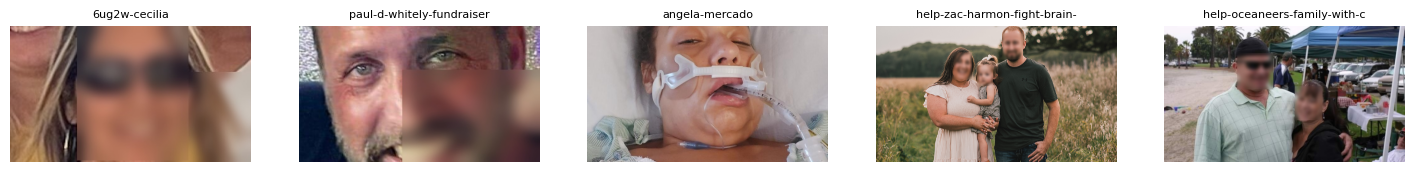

In [ ]:
fig, axes = plt.subplots(1, 5, figsize=(18, 4))
for ax, r in zip(axes, sample.sample(5, random_state=1).itertuples()):
    ax.imshow(Image.open(r.local_image)); ax.set_title(r.campaign_id[:28], fontsize=8); ax.axis("off")
plt.show()

### Image labels: Google Cloud Vision
- **Service:** Google Cloud Vision API, `label_detection`; up to 15 labels per image, lowercased and separated by `; `.
- **Confidence threshold, a decision we changed:** we first kept only labels with confidence ≥ 0.70. That left **185 images (18.5%) with no labels**; images such as screenshots or photos of documents tend to receive only low-confidence labels. Model (i) in Task C uses labels only, so nearly one in five campaigns would have had no input, which would understate what labels can predict. We lowered the threshold to **0.50** and relabeled all 1,000 images. 96 images (9.6%) still had no label at or above 0.50, so we filled them in using other Vision features (see Filling in missing labels). Final coverage: all 999 campaigns have labels: 903 from label detection (confidence ≥ 0.50), 76 from object localization, and 20 from the web-detection best guess.
- We test on 3 images before the full run to check the output.

In [ ]:
VISION_MIN_SCORE = 0.5

if not os.environ.get("GOOGLE_APPLICATION_CREDENTIALS"):
    print("Select your Google Cloud service-account JSON key")
    key_name = list(files.upload())[0]
    os.environ["GOOGLE_APPLICATION_CREDENTIALS"] = os.path.abspath(key_name)

from google.cloud import vision
vision_client = vision.ImageAnnotatorClient()

def get_labels(path):
    resp = vision_client.label_detection(image=vision.Image(content=Path(path).read_bytes()),
                                         max_results=VISION_MAX_LABELS)
    if resp.error.message:
        raise RuntimeError(resp.error.message)
    return "; ".join(l.description.lower() for l in resp.label_annotations if l.score >= VISION_MIN_SCORE)

for r in sample.head(3).itertuples():
    print(r.campaign_id, "->", get_labels(r.local_image))

fishers-friends -> people; happiness; child; smile; fun; leisure; toddler; family; baby & toddler clothing; playing with kids; infant; family taking photos together; family pictures; sibling; love
help-both-of-my-parents-fight-cancer -> portable communications device; mobile phone; communication device; gadget; mobile device; telephony; smartphone
soto-family-needs-medical-expense-relief -> people; clothing; happiness; jeans; trousers; leg; smile; recreation; outdoor recreation; people in nature; woodland; leisure; forest; vacation; bedrock


### Labeling all images
Labels all 1,000 images, saving progress every 25 images. Images already labeled are skipped, so an interrupted run can be restarted without paying twice.

In [ ]:
# Full run, saved every 25 images.
labels_path = OUT / "labels_cache.json"
labels = json.loads(labels_path.read_text()) if labels_path.exists() else {}

for i, r in enumerate(tqdm(sample.itertuples(), total=len(sample), desc="vision")):
    if r.campaign_id in labels:
        continue
    try:
        labels[r.campaign_id] = get_labels(r.local_image)
    except Exception as e:
        print(f"failed: {r.campaign_id} ({e})")
    if i % 25 == 0:
        labels_path.write_text(json.dumps(labels))
labels_path.write_text(json.dumps(labels))
print(f"{len(labels)}/{len(sample)} labeled")

### LLM image descriptions (LLM_stories): Google Gemini
- **Model:** `gemini-3.8-flash` through the Gemini API (Google GenAI Python SDK).
- **Settings:** our requests set temperature to 0.2. Google has deprecated sampling parameters (temperature, top_p, top_k) starting with Gemini 3.6 Flash: they are ignored on these models and will be rejected in future ones. So our temperature setting was most likely ignored, and the stories were generated with the model’s default settings. Factual accuracy rests on the prompt’s instructions (describe only what is visible; do not guess identities, conditions or events) and on our spot checks, not on temperature. Images are resized to at most 1,024 px and sent as JPEG to keep cost down. If a story is cut off or under 60 words, we ask again, up to 5 times.
- **Model choice:** we originally planned to use OpenAI's GPT-4o-mini and switched to Gemini to keep both services with one provider (Google). Our first Gemini model (`gemini-2.5-flash`) is no longer offered to new users, so we used its replacement, `gemini-3.8-flash`, as the API's error message recommended.

**How the prompt was developed** (tested on 3 images each time):
1. **Version 1** asked for 60–100 words covering people, expressions, clothing, objects and setting. The stories were factual, but the model kept describing the blurred faces ("their faces are digitally blurred"). That would have made "blurred" one of the most common words in the LLM_stories BoW models, even though it says nothing about the original campaign photos. And with blurred faces, any description of expressions would be a guess, which breaks the rule against inventing details.
2. **Version 2 (final)** tells the model not to mention the blur or describe expressions, and asks for 70–100 words with a floor of 60.
3. **Short stories:** test stories then stopped at about 35 words. Gemini's internal "thinking" counts against the output-token limit, so stories were cut off when that limit ran out. We raised the limit to 8,192 tokens and added the regenerate-if-cut-off check.

**Final prompt:**
> "Describe this photograph in 70-100 words (never fewer than 60). Describe only what is directly visible: the number of people and their approximate ages, clothing, posture, and actions; animals and objects; the type of setting; and any legible text. Faces in these images are blurred for privacy; do not mention the blurring and do not describe facial expressions. Do not guess names, identities, relationships, medical conditions, causes, or events that are not directly shown. Use neutral, factual language and write a single paragraph."

The cell below runs the final setup on 3 test images.

In [ ]:
%pip install -q google-genai

import os, io, time, textwrap
from getpass import getpass
from google import genai
from google.genai import types

LLM_MODEL = "gemini-3.8-flash"
LLM_TEMPERATURE = 0.2   # sent with each request, but ignored by Gemini 3.6 Flash and later (see LLM stories section)

STORY_PROMPT = (
    "Describe this photograph in 70-100 words (never fewer than 60). Describe only "
    "what is directly visible: the number of people and their approximate ages, "
    "clothing, posture, and actions; animals and objects; the type of setting; and "
    "any legible text. Faces in these images are blurred for privacy; do not mention "
    "the blurring and do not describe facial expressions. Do not guess names, "
    "identities, relationships, medical conditions, causes, or events that are not "
    "directly shown. Use neutral, factual language and write a single paragraph."
)

if not os.environ.get("GEMINI_API_KEY"):
    os.environ["GEMINI_API_KEY"] = getpass("Gemini API key: ")
gemini = genai.Client(api_key=os.environ["GEMINI_API_KEY"])

def to_jpeg_bytes(path, max_side=1024):
    with Image.open(path) as im:
        im = im.convert("RGB"); im.thumbnail((max_side, max_side))
        buf = io.BytesIO(); im.save(buf, format="JPEG", quality=85)
    return buf.getvalue()

def get_story(path, retries=5):
    text = ""
    for attempt in range(retries):
        try:
            resp = gemini.models.generate_content(
                model=LLM_MODEL,
                contents=[types.Part.from_bytes(data=to_jpeg_bytes(path), mime_type="image/jpeg"),
                          STORY_PROMPT],
                config=types.GenerateContentConfig(temperature=LLM_TEMPERATURE,
                                                   max_output_tokens=8192),
            )
            text = (resp.text or "").strip()
            finish = str(resp.candidates[0].finish_reason) if resp.candidates else "NO_RESPONSE"
            if "MAX_TOKENS" in finish or len(text.split()) < 60:
                print(f"  retrying ({len(text.split())} words, finish={finish})")
                continue
            return text
        except Exception as e:
            if "429" in str(e) or "RESOURCE_EXHAUSTED" in str(e):
                time.sleep(10 * (attempt + 1))
            else:
                raise
    if len(text.split()) >= 40:
        return text
    raise RuntimeError("no usable story (rate limit or blocked)")

# Test on 3 images
for r in sample.head(3).itertuples():
    s = get_story(r.local_image)
    plt.figure(figsize=(3, 3)); plt.imshow(Image.open(r.local_image)); plt.axis("off"); plt.show()
    print(f"[{len(s.split())} words]\n" + textwrap.fill(s, 120) + "\n")

### Generating all image descriptions
Generates a story for all 1,000 images, saving progress every 25. Our API credit ran out partway through the run, and requests made after that point returned empty stories. We deleted those empty results, added credit, and generated them again with the **same model, prompt and settings**. We did not finish the run with a different model, which would have made the stories inconsistent with each other.

For one campaign (`erins-lescanos-medical-and-other-expenses`) Gemini returned no response on all 5 attempts, most likely because its safety filter blocked the image. This campaign is excluded in the next step.

In [ ]:
# Full run, saved every 25 images.
stories_path = OUT / "stories_cache.json"
stories = json.loads(stories_path.read_text()) if stories_path.exists() else {}

for i, r in enumerate(tqdm(sample.itertuples(), total=len(sample), desc="llm")):
    if r.campaign_id in stories:
        continue
    try:
        stories[r.campaign_id] = get_story(r.local_image)
    except Exception as e:
        print(f"failed: {r.campaign_id} ({e})")
    if i % 25 == 0:
        stories_path.write_text(json.dumps(stories))
stories_path.write_text(json.dumps(stories))
print(f"{len(stories)}/{len(sample)} stories")

In [ ]:
files.download("task_a_out/stories_cache.json")

### Assembling the initial dataset
Joins the labels and stories to the sample and drops the one campaign without a story, leaving **999 campaigns**. The three text fields are kept in separate columns: `image_labels`, `LLM_stories`, and `description` (the campaign's `clean_description`).

We retain `raised` as the fundraising outcome for Task B. We also retain `goal`, `launch_date`, `country`, and `num_photo_main_body` as campaign metadata.

The archived goal and photo count may include changes made after launch. They should be used as launch-time controls only if their original values can be established.

Donations, comments, and updates are excluded from the predictor dataset because they accumulate after launch and could reveal information about fundraising outcomes.

**Story length:** median 92 words (range 75–119). 13 stories run a little over 100 words, which we kept, since the assignment asks for *approximately* 60–100 words.

In [ ]:
selection_log.pop("has_image_in_zip", None)

labels  = json.loads((OUT / "labels_cache.json").read_text())
stories = json.loads((OUT / "stories_cache.json").read_text())

final = sample.copy()
final["image_labels"] = final["campaign_id"].map(labels)
final["LLM_stories"]  = final["campaign_id"].map(stories)
final["description"]  = final["clean_description"]

failed = final["image_labels"].isna() | final["LLM_stories"].isna()
print("Excluded (no label or story):", list(final.loc[failed, "campaign_id"]))
selection_log["llm_blocked_or_failed"] = int(failed.sum())
final = final[~failed].reset_index(drop=True)
selection_log["final_dataset"] = len(final)

wc = final["LLM_stories"].str.split().str.len()
print(f"Story length: median {wc.median():.0f} words, range {wc.min()}-{wc.max()}, "
      f"{((wc < 60) | (wc > 100)).sum()} outside 60-100")
n_empty = (final["image_labels"].str.strip() == "").sum()
print(f"Images with no label at confidence >= {VISION_MIN_SCORE}: {n_empty}")

cols = ["campaign_id", "category", "raised", "goal", "launch_date", "country",
        "num_photo_main_body", "main_image", "image_labels", "LLM_stories", "description"]
final = final[cols]
final.to_csv(OUT / "task_a_dataset.csv", index=False)
print(f"Saved task_a_dataset.csv ({len(final)} rows)")
final[["campaign_id", "image_labels", "LLM_stories", "description"]].head()

### Filling in missing labels and reusing the completed results

The initial Google Cloud Vision labeling run left 96 campaigns without labels at confidence ≥ 0.50. In a subsequent API run, we processed these images using additional Vision features, prioritizing label detection without our confidence filter, followed by object localization and web-detection best-guess labels.

The completed dataset contains:

| Label source | Campaigns |
|---|---:|
| Standard label detection, confidence ≥ 0.50 | 903 |
| Object localization | 76 |
| Web-detection best-guess labels | 20 |
| Total | 999 |

All 999 selected campaigns now have nonempty `image_labels`. The `label_source` column records the method used for each campaign. No campaigns were added or removed during this step.

The fallback labels are generally shorter and less detailed than standard labels. Web-best-guess labels are inferred using similar online images, so they may represent an image's broader topic rather than directly detected objects. These differences should be considered when interpreting the image-label models in Task C.

Because the three methods capture different information, **`image_labels` is not a uniform measure of visual content across campaigns.** Standard labels name detected visual concepts, object localization names discrete objects, and web best guesses may reflect how similar images are described online. For 96 campaigns (9.6%) the field therefore contains a different and usually thinner kind of evidence than for the other 903.

The code below reuses the completed dataset. It preserves recorded label sources, restores saved fallback information where available, and synchronizes the final CSV and caches. It does not repeat the image-labeling API requests.

The saved output contains 999 campaigns, zero empty image-label fields, and the three source counts shown above.

In [ ]:
from pathlib import Path
import json
import pandas as pd

OUT = Path("task_a_out")
OUT.mkdir(exist_ok=True)

possible_paths = [
    OUT / "task_a_dataset.csv",
    Path("task_a_dataset.csv")
]

DATA = next(
    (path for path in possible_paths if path.exists()),
    None
)

if DATA is None:
    raise FileNotFoundError("Upload the updated task_a_dataset.csv.")

final = pd.read_csv(DATA, keep_default_na=False)

# Confirms that the updated dataset contains labels and their sources.
if "label_source" not in final.columns:
    raise ValueError(
        "Use the updated CSV containing the label_source column."
    )

if final["image_labels"].str.strip().eq("").any():
    raise ValueError("Some image-label fields are still empty.")

# Restores fallback provenance from the cache if it is available.
fill_path = OUT / "labels_fallback.json"

filled = (
    json.loads(fill_path.read_text())
    if fill_path.exists()
    else {}
)

for idx in final.index:
    cid = final.at[idx, "campaign_id"]
    cached = filled.get(cid)

    if cached and cached.get("labels"):
        final.at[idx, "image_labels"] = "; ".join(cached["labels"])
        final.at[idx, "label_source"] = cached["source"]

# Saves fallback records from the completed CSV.
for row in final.itertuples(index=False):
    if row.label_source != "vision_label":
        filled[row.campaign_id] = {
            "labels": row.image_labels.split("; "),
            "source": row.label_source
        }

fill_path.write_text(json.dumps(filled, indent=2))

# Synchronizes the text caches with the final dataset.
for column, filename in [
    ("image_labels", "labels_cache.json"),
    ("LLM_stories", "stories_cache.json")
]:
    cache_path = OUT / filename

    cache = (
        json.loads(cache_path.read_text())
        if cache_path.exists()
        else {}
    )

    cache.update(dict(zip(final["campaign_id"], final[column])))
    cache_path.write_text(json.dumps(cache, indent=2))

# Saves consistent copies for subsequent tasks.
final.to_csv(OUT / "task_a_dataset.csv", index=False)
final.to_csv("task_a_dataset.csv", index=False)

print(f"Campaigns: {len(final):,}")
print(
    "Empty image-label fields:",
    final["image_labels"].str.strip().eq("").sum()
)

print("\nLabel source counts:")
print(final["label_source"].value_counts().to_string())

print("\nUpdated CSV and caches saved successfully.")

Campaigns: 999
Empty image-label fields: 0

Label source counts:
label_source
vision_label                  903
vision_object_localization     76
vision_web_best_guess          20

Updated CSV and caches saved successfully.


### Quality check

**Manual review (30 campaigns):** we first reviewed 5 random campaigns, then 25 more (random, seed 2026), comparing each image with its labels and description. For the 25, we checked for invented relationships or identities (0 found), incorrect objects (3), incorrect readings of text in the image (0), generic descriptions with little useful information (0), and descriptions that repeat fundraising text visible in the image (0). The three incorrectly identified objects were all diractly related to things in the background of an image, and never the main subject.  The completed review sheet is `task_a_manual_review.csv`.

**Automated screen (all 999):** we searched every description for content that could indicate invented or non-visual information:

| Check | Descriptions flagged | Finding |
|---|---:|---|
| Relationship words (mom, dad, family, …) | 12 (1.2%) | 11 come from text visible in the image (e.g., a shirt reading "DAD", a cake reading "Happy Birthday Dad!"); 1 describes a setting ("single-family homes"). None infers a relationship. |
| Medical-condition words (cancer, disease, …) | 5 (0.5%) | All come from visible text, such as shirts or posters ("TOUGHER THAN CANCER", "HEART DISEASE"). None invents a diagnosis. |
| Fundraising words (donate, fundraiser, …) | 2 (0.2%) | Both transcribe text in the image (a "DONATE NOW" button; a fundraiser graphic). |
| Quoted text read from the image | 329 (32.9%) | Mostly short text (brand names, numbers, signs), but some descriptions transcribe campaign messages, people's names, or social-media handles shown in the image. |

**Conclusion:** we found no relationships or diagnoses invented by the model. The manual review did find occasional factual slips: [3] of 25 descriptions misdescribed a visible object, so individual descriptions can contain small errors even though none invented relationships, identities or diagnoses. Every flagged case traced back to text visible in the image, which the prompt asked the model to report. However, because about a third of descriptions transcribe visible text, some `LLM_stories` contain campaign-specific information (messages, names) that originates from fundraising graphics rather than from purely visual content. This should be considered when interpreting Task C. Thirty manually reviewed cases cannot establish the accuracy of all 999 descriptions.

In [ ]:
local = dict(zip(sample["campaign_id"], sample["local_image"]))
for r in final.sample(5, random_state=7).itertuples():
    plt.figure(figsize=(3, 3)); plt.imshow(Image.open(local[r.campaign_id])); plt.axis("off"); plt.show()
    print("LABELS:", r.image_labels)
    print("STORY: ", textwrap.fill(r.LLM_stories, 120), "\n")

In [ ]:
%pip install -q remotezip

In [ ]:
# Automated screen of all 999 image descriptions
import re
import pandas as pd
from pathlib import Path

DATA = next(p for p in [Path("task_a_out/task_a_dataset.csv"), Path("task_a_dataset.csv")] if p.exists())
qa = pd.read_csv(DATA, keep_default_na=False)

checks = {
    "relationship_words": r"\b(?:mother|father|mom|dad|husband|wife|son|daughter|brother|sister|siblings?|"
                          r"couple|family|parents?|grand(?:mother|father|parents?)|spouse|boyfriend|girlfriend)\b",
    "medical_condition_words": r"\b(?:cancer|chemo\w*|diagnos\w*|tumou?r|leukemia|illness|disease|stroke|sick)\b",
    "fundraising_words": r"\b(?:gofundme|donat\w*|fundrais\w*|fund|campaign)\b",
    "quoted_text_read": r"\"[^\"]{2,}\"|“[^”]{2,}”",
}
for name, pattern in checks.items():
    qa[name] = qa["LLM_stories"].str.contains(pattern, flags=re.IGNORECASE, regex=True)

summary = pd.DataFrame({
    "descriptions flagged": qa[list(checks)].sum(),
    f"% of {len(qa)}": (qa[list(checks)].mean() * 100).round(1),
})
print("Automated screen of all descriptions (a flag means 'review', not 'error'):")
print(summary.to_string())

for name, pattern in checks.items():
    ex = qa[qa[name]].head(3)
    print(f"\n--- {name}: examples ---")
    for r in ex.itertuples():
        hits = sorted({m.group(0).lower() for m in re.finditer(pattern, r.LLM_stories, flags=re.IGNORECASE)})
        print(f"  {r.campaign_id}: {hits}")

Automated screen of all descriptions (a flag means 'review', not 'error'):
                         descriptions flagged  % of 999
relationship_words                         12       1.2
medical_condition_words                     5       0.5
fundraising_words                           2       0.2
quoted_text_read                          329      32.9

--- relationship_words: examples ---
  donate-to-help-luke-fight-this-battle: ['family']
  medical-care-for-tate: ['brother']
  supporting-the-burgett-family: ['dad']

--- medical_condition_words: examples ---
  help-support-alina-and-her-daughter-athena: ['cancer']
  help-me-pay-expensive-cancer-bills: ['cancer', 'leukemia']
  support-raquel-castrocorazzinis-family: ['disease']

--- fundraising_words: examples ---
  donate-to-help-luke-fight-this-battle: ['donate']
  josie-fundraiser: ['fundraiser']

--- quoted_text_read: examples ---
  addilynn-receive-longterm-care: ['"ride"']
  ta-canty-with-medical-expenses: ['"ter"']
  rvykn-zacha

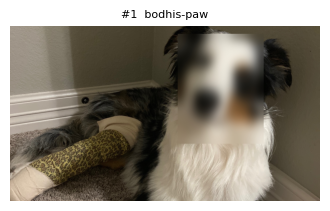

LABELS (vision_label): dog; fur; carnivores; canidae; terrier; toy dog; tail; paw; pet supply
DESCRIPTION: In an indoor setting, a long-haired dog with black, grey, white, and tan fur lies resting on a carpeted floor.
The dog is positioned in the corner of a room against light gray walls with white baseboards. One of the dog's
legs is heavily bandaged, featuring layers of tan fabric wrap secured at the ends and a central section
wrapped in a yellow and black leopard-print patterned bandage. The dog’s body is extended along the floor,
with its fluffy white chest fur prominent in the foreground. No people or legible text are visible in the
scene. 



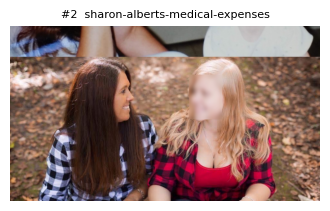

LABELS (vision_label): hair; lips; happiness; beauty; plaid; summer; youth; long hair; tartan; friendship; brown hair; fun; people in nature; leisure; layered hair
DESCRIPTION: Two young adult women sit side-by-side outdoors in a wooded setting. The woman on the left has long, straight
brown hair and wears a black-and-white checkered button-up shirt, turned slightly toward the person beside
her. The woman on the right has long, wavy blonde hair and wears an open red-and-black checkered shirt over a
red scoop-neck top, accessorized with a thin necklace and bracelet. Both are seated on ground covered in
fallen brown leaves, with trees visible in the soft-focus background. A cropped section of another photograph
appears along the top edge. 



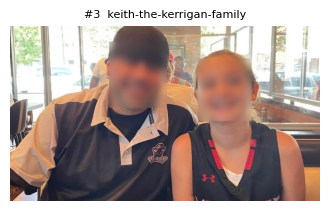

LABELS (vision_object_localization): clothing; person; top; shirt
DESCRIPTION: An adult and a young person are seated beside each other inside a restaurant booth. The adult on the left
wears a dark cap and a short-sleeved, black-and-white collared shirt with a team emblem reading "RAIDERS,"
worn over a dark undershirt with an attached lanyard. The youth on the right wears a sleeveless dark athletic
jersey featuring pinkish-red stripes near the V-neck and a matching manufacturer logo, layered over a white
top. Behind them, large glass windows and transparent booth partitions show daytime sunlight, outdoor
greenery, parked cars, and other patrons seated in the background. 



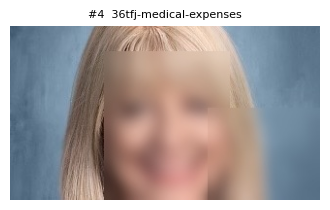

LABELS (vision_label): lips; facial expression; blond; portrait photography; step cutting
DESCRIPTION: This close-up portrait shows one person positioned in the center against a solid blue background that features
slight texture and variations in tone. The individual appears to be an adult with straight, light blonde hair
that falls around the face and includes straight-cut bangs covering the upper forehead. The subject faces
directly forward toward the camera in a frontal headshot orientation. The framing closely focuses on the head,
leaving little to no clothing visible. There are no other people, objects, or inscriptions in the frame. 



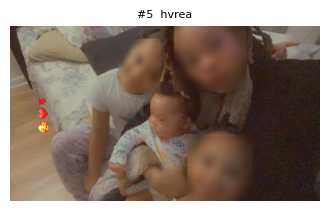

LABELS (vision_label): child; toddler; infant; baby & toddler clothing; comfort
DESCRIPTION: Four individuals are gathered together indoors beside a bed. On the left, a child sits wearing a white short-
sleeved shirt and patterned pants. In the center, an infant wearing a long-sleeved patterned onesie rests
against a fluffy stuffed animal while being held. Behind the infant sits another person wearing dark clothing,
while a fourth person is partially visible in the lower foreground. The indoor setting features a light wood-
look floor and a bed with floral bedding and pillows. Three small emoji icons appear along the left edge. 



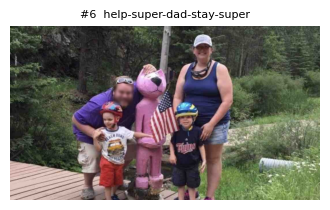

LABELS (vision_label): recreation; smile; leisure; fun; vacation; child; happiness; holiday; toddler; stuffed toy; sunglasses; toy; lap
DESCRIPTION: Two adults and two young children stand on a wooden boardwalk in a wooded outdoor area. On the left, an adult
in a purple shirt and khaki shorts leans forward, touching a pink carved wooden figure holding a small
American flag. Beside him, a child in a red helmet wears a t-shirt reading "BEACH BUMS." Another child wears a
blue and yellow helmet with a dark shirt reading "Twins." To the right, an adult stands wearing a white cap,
blue tank top, and denim shorts. 



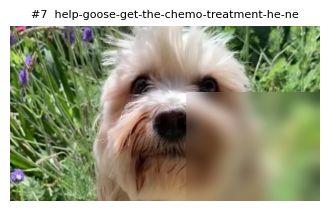

LABELS (vision_label): dog; vertebrate; carnivores; snout; terrier; toy dog; small terrier; puppy; canidae; terrestrial animal; fur; poodle crossbreed; working animal; cavachon; water dog
DESCRIPTION: This close-up outdoor photograph features a small, fluffy dog with light cream-colored fur. The dog's face is
centered in the frame, showing dark eyes, a black nose, and slightly darker, reddish-brown fur surrounding its
muzzle. Its fur is soft, shaggy, and slightly tousled on top of its head. The background consists of lush
green vegetation, including tall blades of grass, leafy plants, and several stalks of small purple flowers.
The scene is brightly illuminated by natural daylight, highlighting the textures of both the animal's coat and
the surrounding garden foliage. 



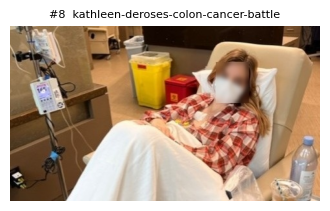

LABELS (vision_label): patient; medical; health care; hospital; comfort; medical equipment; clinic; display device; medical procedure; hospital bed; electronics; bed
DESCRIPTION: An adult reclines in a padded beige chair in a medical setting, resting against a white pillow. The person has
long blonde hair, wears a white face mask, and is dressed in a red and white plaid shirt with a white blanket
covering their legs. A medical dressing is visible on the upper chest. To the left, an IV pole holds fluid
bags, tubing, and an electronic pump displaying the number "165." In the background sit a yellow bin and a red
container. A water bottle and plastic cup rest on the right. 



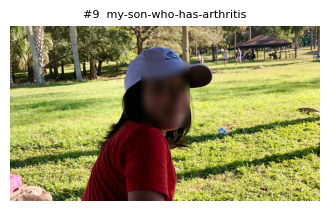

LABELS (vision_label): grass; recreation; lawn; leisure; cap; park; baseball cap; cricket cap; vacation; visor
DESCRIPTION: In a sunny outdoor park, a young person wearing a red short-sleeved shirt and a light-colored baseball cap
sits on a lush green lawn, turned toward the viewer. In the grass behind them rests a small white and blue
soccer ball. The background features a wide, grassy open area dotted with shadows from tall trees. In the
distance, several people walk across the field, while a few others gather under a large covered pavilion with
picnic tables. Sunlight illuminates the surrounding green grass, trees, and distant park grounds. 



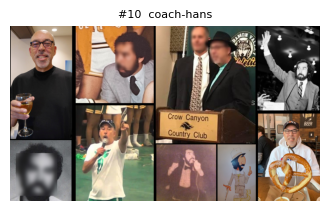

LABELS (vision_label): facial hair; beard; moustache
DESCRIPTION: This photo collage displays several pictures and an illustration of an adult man at various stages of life. On
the far left, he wears glasses and a black shirt while holding a glass of amber liquid. Other sections show
him younger with dark curly hair and a beard, dressed in formal suits, including one where he raises his hand.
Two men in suits stand behind a wooden podium reading "Crow Canyon Country Club." Additional scenes show him
speaking into a microphone in a gym, and sitting behind a giant pretzel on a stand near a "BEER" sign. 



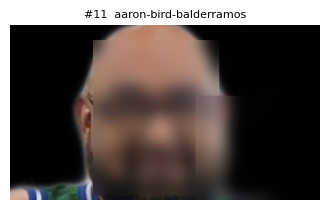

LABELS (vision_label): facial expression; close-up; facial hair; selfie; buzz cut; moustache
DESCRIPTION: A close-up photograph depicts a single adult against a solid black background. The person appears to be an
adult male facing forward directly toward the camera in a centered portrait composition. The individual is
bald and wears eyeglasses, with the thin frame visible near the ear on the left side of the frame, along with
visible dark facial hair along the jawline. A small portion of clothing is visible at the bottom left,
consisting of a green garment with blue and white trim. The background remains entirely dark and featureless. 



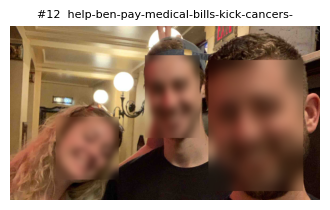

LABELS (vision_object_localization): clothing; person; top
DESCRIPTION: Three young adults pose closely together indoors in a warmly lit setting, likely a restaurant or bar. The
person on the left has wavy blonde hair with pink highlights and wears dark attire. The person in the center
wears a backward blue baseball cap and a black crew-neck shirt, holding two fingers up behind their head in a
peace or bunny-ear gesture. The person on the right has short dark hair and a beard, wearing a dark shirt. In
the background, beige walls feature decorative arches, illuminated globe wall sconces, and a glowing red exit
sign above a doorway. 



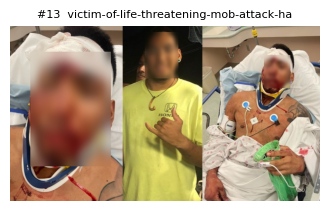

LABELS (vision_label): patient; hospital; medical procedure; medical; medical equipment; health care
DESCRIPTION: This composite image consists of three panels. In the center, a young adult stands indoors wearing a lime-
green t-shirt featuring the text "HON" and a logo, a hook pendant necklace, and an earring, while raising one
hand with extended thumb and pinky. Another individual partially appears behind his shoulder. The flanking
panels show the young adult lying in a hospital bed with head bandages and a blue and white cervical collar.
He is bare-chested with visible tattoos, monitoring sensors on his torso, and red fluid marks on his skin and
the white bedding. 



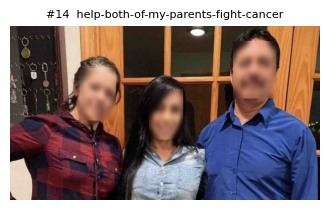

LABELS (vision_label): portable communications device; mobile phone; communication device; gadget; mobile device; telephony; smartphone
DESCRIPTION: Three adults stand together indoors, posed side by side and facing forward toward the camera. On the left, an
individual with dark hair tied back wears a red and dark blue plaid button-down shirt. In the center, a person
with long, dark hair wears a light blue denim-style shirt. On the right, a person with short dark hair and a
mustache wears a solid royal blue long-sleeve collared shirt. Behind them is a wooden multi-pane glass door or
partition, and to the left, a dark vertical board holds several hanging metal keychains. 



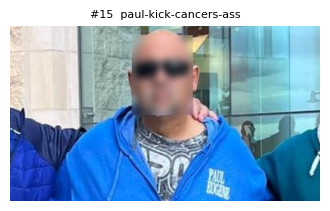

LABELS (vision_label): law enforcement; police; security
DESCRIPTION: This photograph shows an adult man standing outdoors, flanked closely by two other individuals who are
partially visible on either side. The central man has a bald head and wears dark sunglasses, a patterned grey-
and-white t-shirt, and a royal blue zip-up hoodie with the white printed text "PAUL EUGENE" on the chest. A
hand rests on his left shoulder. The person on the left wears a blue quilted jacket, while the person on the
right wears a teal hooded garment. They stand before a modern building facade with light-colored stone pillars
and large glass panels. 



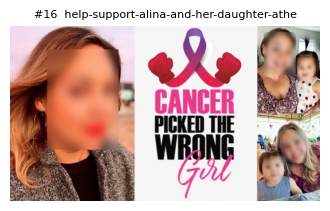

LABELS (vision_label): child
DESCRIPTION: This collage features three photographs and a central graphic design. On the left, an adult with shoulder-
length hair wears a gray textured jacket, a dark top, and hoop earrings. The center display shows a pink-and-
purple ribbon with red boxing gloves above the text "CANCER PICKED THE WRONG Girl." On the upper right, an
adult wearing a floral top poses with a young child dressed in a polka-dot garment. Below them, an adult sits
indoors beside a young child wearing a striped sleeveless shirt. 



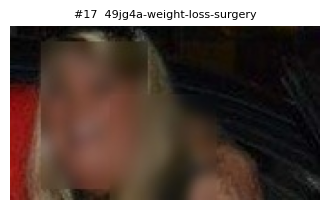

LABELS (vision_web_best_guess): girl
DESCRIPTION: This close-up photograph depicts a single adult person positioned toward the left of the frame. The individual
has light blonde hair that falls around the head and shoulders. Part of the person's upper body is visible,
appearing to wear clothing with textured fabric in muted brownish or tan tones. To the right, dense black
feathery or frilled textures extend outward, possibly from a costume, garment, or accessory. On the far left
side, a section of bright red background or fabric is visible, while the rest of the setting behind the person
remains dark and indistinct. No text is visible. 



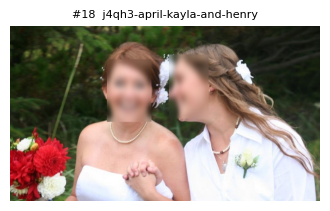

LABELS (vision_label): hairstyle; jewellery; beauty; bridal clothing; bride; wedding dress; gown; petal; ceremony; strapless dress; wedding; bridal veil; necklace; wedding ceremony supply; cut flowers
DESCRIPTION: This photograph shows two adult women outdoors against a background of lush green foliage and trees. The woman
on the left has reddish-brown hair styled in an updo with a white floral hairpiece, and she wears a white
strapless dress with a pearl necklace while holding a bouquet of red and white flowers. Beside her, the woman
on the right has long, wavy light-brown hair adorned with a white flower. She wears a white collared button-up
shirt with a white floral boutonniere and two necklaces, leaning toward the other woman as they hold hands. 



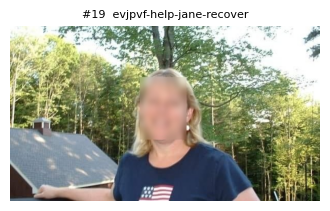

LABELS (vision_label): siding; garden buildings; backyard
DESCRIPTION: In this outdoor photograph, one adult woman stands facing the camera with her body angled slightly toward the
viewer. She has shoulder-length blonde hair, wears an earring, and is dressed in a dark blue short-sleeved
t-shirt featuring an American flag graphic across the front. Her right arm rests against a dark railing on the
left. The background consists of dense green trees and foliage under a bright sky. Partially visible in the
lower left is the pitched, gray-shingled roof of a building topped with a cupola. 



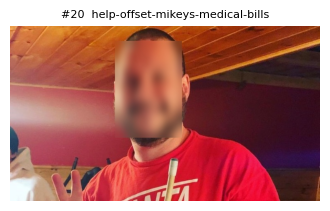

LABELS (vision_label): facial hair; beard; moustache; muscle; active shirt; flesh
DESCRIPTION: In this indoor photograph, an adult man stands in the foreground, facing the camera. He has short dark hair
and a beard, wearing a red short-sleeved t-shirt featuring partial white lettering. With his raised hand, he
forms a peace sign, while also holding a pool cue with a white tip upright. On the left edge, a portion of
another person appears wearing a white hooded sweatshirt. The room features an angled ceiling finished with
wooden planks, vibrant red walls, and dark background furniture. 



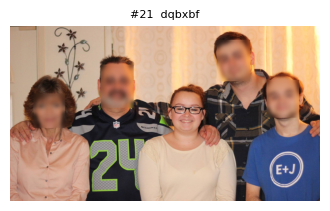

LABELS (vision_label): happiness; smile; active shirt; fun; selfie; long-sleeved t-shirt; hoodie
DESCRIPTION: Five people stand closely together indoors before patterned curtains and a decorative floral wall ornament. On
the left, a woman wears a light pink button-up shirt. Next to her, a man wears a dark blue Seattle Seahawks
jersey displaying neon green number "24", an "NFL" emblem, and the word "SEAHAWKS". In the center, a woman
wearing dark-framed glasses is dressed in a cream-colored top. Standing behind her, a man wears a dark plaid
shirt. On the right, another man wears a blue t-shirt with a white circle reading "E+J". Hands rest on
adjacent shoulders across the group. 



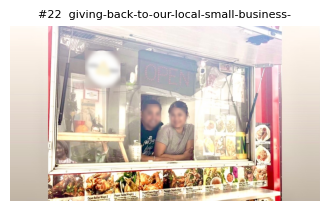

LABELS (vision_label): food; food truck; customer; fast food; shopkeeper; street food; fast food restaurant; meat; staple food; cleanliness
DESCRIPTION: In this photograph, two adults stand inside the open service window of a food truck. The person on the right
wears a grey short-sleeved shirt and leans forward on the counter, while the person beside them wears a dark
graphic t-shirt. A third individual is partially visible through the glass on the left. An illuminated red
sign above displays the word "OPEN." Below the opening, laminated menu strips show photos of cooked chicken
wings alongside text labels including "Cajun Butter Wings," "Pepper Salted Wings," and "Peanut Sauce Wings." 



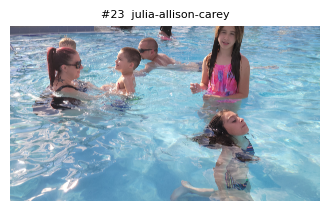

LABELS (vision_label): swimming pool; fun; recreation; leisure; fluid; summer; happiness; swimsuit; vacation; child; outdoor recreation; smile; holiday; bathing; swimsuit top
DESCRIPTION: Several individuals are in an outdoor swimming pool filled with clear blue water. On the left, an adult woman
wearing sunglasses, a dark swimsuit, and a high ponytail supports a young boy wearing swim trunks in the
water. Behind them, an adult man wearing sunglasses swims forward. To the right, an older girl with long dark
hair stands facing the camera in a pink patterned swim top, while in the lower right, a younger girl in a
striped swimsuit floats with her head tilted back. Sunlight creates bright, rippling patterns across the
pool's surface. 



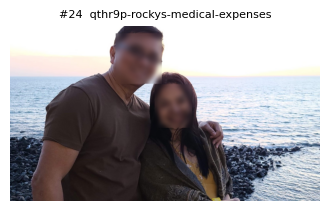

LABELS (vision_label): sea; coast; ocean; fun; vacation; beach; coastal and oceanic landforms; shore; people in nature; leisure; wind wave; wave; travel; holiday; happiness
DESCRIPTION: Two adults, a man and a woman, pose closely together outdoors against a coastal landscape at dusk or dawn. The
man on the left wears a short-sleeved brown V-neck shirt and rests his arm around the woman's shoulder. The
woman wears a yellow garment draped with a dark patterned shawl, and a yellow band is visible around her
wrist. Behind them, a rocky shoreline composed of dark stones slopes down to a broad body of water stretching
toward the horizon under a softly lit sky. 



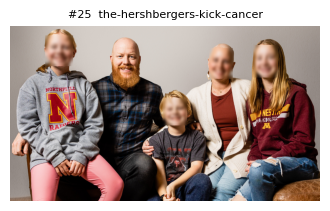

LABELS (vision_label): people; happiness; smile; jacket; fun; child; beard; facial hair; lap; denim; hoodie; family; family pictures; toddler; plaid
DESCRIPTION: Five people sit closely together on a brown couch against a plain gray background. On the far left, a girl
wears pink pants and a gray hooded sweatshirt with red text reading "NORTHFIELD RAIDERS" around an "N." Next
to her, a bearded adult man wears a dark plaid button-down shirt. In the center, a young boy sits in a dark
graphic t-shirt and jeans. Beside him, an adult wears a cream cardigan over a reddish-brown shirt and light
jeans. On the far right, a girl wears ripped blue jeans and a maroon sweatshirt reading "MINNESOTA GOLDEN
GOPHERS." 

Saved task_a_manual_review.csv: fill in Y/N per check while reviewing the 25 images above.


In [ ]:
# Manual review of 25 more random campaigns
import textwrap
import matplotlib.pyplot as plt
from io import BytesIO
from PIL import Image
from remotezip import RemoteZip

PHOTOS_ZIP_URL = "https://zenodo.org/records/8287320/files/Photos.zip?download=1"
first_check = set(qa.sample(5, random_state=7)["campaign_id"])        # the 5 already reviewed
review = qa[~qa["campaign_id"].isin(first_check)].sample(25, random_state=2026).reset_index(drop=True)

with RemoteZip(PHOTOS_ZIP_URL) as z:
    for i, r in review.iterrows():
        img = Image.open(BytesIO(z.read(r["main_image"])))
        plt.figure(figsize=(4, 4)); plt.imshow(img); plt.axis("off")
        plt.title(f"#{i + 1}  {r['campaign_id'][:40]}", fontsize=8); plt.show()
        print(f"LABELS ({r['label_source']}): {r['image_labels']}")
        print("DESCRIPTION:", textwrap.fill(r["LLM_stories"], 110), "\n")

# Review sheet: fill in Y/N for each check after looking at each image
sheet = review[["campaign_id", "label_source"]].copy()
for col in ["invented_relationship_or_identity", "wrong_object", "wrong_text_reading",
            "generic_low_information", "reveals_fundraising_text", "notes"]:
    sheet[col] = ""
sheet.insert(0, "review_no", range(1, 26))
sheet.to_csv("task_a_manual_review.csv", index=False)
print("Saved task_a_manual_review.csv: fill in Y/N per check while reviewing the 25 images above.")

### Summary: selection, services and prompt

| Step | Campaigns |
|---|---:|
| All records | 14,961 |
| Medical | 3,580 |
| After removing campaigns listed under more than one category | 3,512 |
| Has funds raised and a description | 3,512 |
| Has cover photo | 3,511 |
| Homepage image in archive | 2,943 |
| Random sample with buffer (seed 42) | 1,100 |
| Unusable images in the buffer | 0 |
| Sample kept | 1,000 |
| Excluded because no LLM story was returned | 1 |
| **Final dataset** | **999** |

**Image-label services:** Google Cloud Vision standard label detection, with confidence ≥ 0.50 and up to 15 labels per image, provided labels for 903 campaigns. Object localization provided fallback labels for 76 campaigns, and web-detection best guesses provided labels for 20 campaigns. All 999 campaigns have nonempty image labels, and `label_source` records the method used.

**Image-story model:** Google Gemini `gemini-3.8-flash`. Requests included temperature=0.2, which the model ignores. The complete image-description prompt is provided in the “LLM image descriptions (LLM_stories): Google Gemini” section above.

**Saved output:** The completed Task A dataset contains 999 campaigns and 12 columns. It retains `image_labels`, `LLM_stories`, and `description` as separate text fields.

In [ ]:
from pathlib import Path
import pandas as pd

OUT = Path("task_a_out")

summary_df = pd.read_csv(
    OUT / "task_a_dataset.csv",
    keep_default_na=False
)

print(f"Final campaigns: {len(summary_df):,}")
print(
    f"Unique campaigns: "
    f"{summary_df['campaign_id'].nunique():,}"
)
print(f"Dataset columns: {summary_df.shape[1]}")

print("\nLabel source counts:")
print(summary_df["label_source"].value_counts().to_string())

print("\nEmpty text fields:")
for column in ["image_labels", "LLM_stories", "description"]:
    count = summary_df[column].str.strip().eq("").sum()
    print(f"{column}: {count}")

word_counts = summary_df["LLM_stories"].str.split().str.len()

print(
    f"\nStory length: median {word_counts.median():.0f} words; "
    f"range {word_counts.min()}–{word_counts.max()} words"
)

print(
    "Stories outside 60–100 words:",
    int(((word_counts < 60) | (word_counts > 100)).sum())
)

print(
    "\nImage service: Google Cloud Vision—standard label "
    "detection, object localization, and web-best-guess labels."
)

print("Story model: gemini-3.8-flash.")
print(
    "Requests included temperature=0.2; "
    "this model ignores that parameter."
)
print("The complete image-description prompt appears above.")

### Output and limitations

The completed `task_a_dataset.csv` contains **999 Medical campaigns and 12 columns**. It is the input for Tasks B–D.

The three text fields remain separate:
- `image_labels`: image-derived labels from Google Cloud Vision.
- `LLM_stories`: factual image descriptions generated using Gemini.
- `description`: the campaign description provided in the dataset.

The `label_source` column identifies how each campaign's image labels were obtained:

| Label source | Campaigns |
|---|---:|
| Standard label detection, confidence ≥ 0.50 | 903 |
| Object localization | 76 |
| Web-detection best-guess labels | 20 |
| Total | 999 |

All 999 campaigns have nonempty image labels, LLM stories, campaign descriptions, and recorded fundraising amounts. Filling the missing labels did not change the selected campaigns or their fundraising amounts.

The completed dataset and synchronized caches are packaged in `task_a_files.zip`:
- `task_a_dataset.csv`
- `labels_cache.json`
- `stories_cache.json`
- `labels_fallback.json`

### Limitations

**Blurred faces:** The archived images have blurred faces, which limits reliable interpretation of facial expressions and other facial details. The information extracted from these images may differ from what donors saw in the original campaign photographs.

**Different image formats:** Some main images are screenshots, documents, graphics, or collages. These can produce generic or incomplete labels, so the extracted text may not capture all relevant visual information.

**Different labeling methods:** The 96 fallback cases use object localization or web-best-guess labels. These labels are generally shorter and less detailed than standard labels. Consequently, the amount and type of information in `image_labels` vary across campaigns. The final `image_labels` field should therefore not be treated as a fully consistent measure of visual content.

**Web-derived information:** Web-best-guess labels use information inferred from similar online images. They may describe an image's broader topic rather than directly visible objects, which limits interpreting the label-based models as using visual content alone.

**Selection:** Of the 3,511 otherwise eligible Medical campaigns, 568 lacked a matching homepage image in the archive and could not be sampled. The final sample may therefore differ from campaigns without available main images and should not be assumed to represent all Medical campaigns or other fundraising categories.

**Generated descriptions:** Generated descriptions: the prompt restricts descriptions to visible content, but generated text can still contain mistakes. In a manual review of 30 campaigns, we found no invented relationships, identities or diagnoses, and no misread text, but [3] descriptions misdescribed a visible object. An automated screen of all 999 found that every relationship, medical or fundraising term came from text visible in the image rather than from the model’s inference. About a third of descriptions (329) transcribe visible text, so some contain campaign messages, names or handles from fundraising graphics. These checks reduce but do not eliminate the chance of errors in individual descriptions.

**Story length:** Stories have a median length of 92 words and range from 75 to 119 words. Thirteen exceed 100 words. These were retained because the assignment requests approximately 60–100 words.

In [ ]:
from pathlib import Path
import zipfile
from google.colab import files

OUT = Path("task_a_out")

filenames = [
    "task_a_dataset.csv",
    "labels_cache.json",
    "stories_cache.json",
    "labels_fallback.json"
]

# Checks every file before creating the ZIP.
missing = [
    filename for filename in filenames
    if not (OUT / filename).is_file()
]

if missing:
    raise FileNotFoundError(f"Missing files: {missing}")

# Creates the ZIP and add the saved files.
zip_path = Path("task_a_files.zip")

with zipfile.ZipFile(
    zip_path, "w", compression=zipfile.ZIP_DEFLATED
) as z:
    for filename in filenames:
        z.write(OUT / filename, arcname=filename)

print("ZIP created successfully. Files included:")
for filename in filenames:
    print(f"- {filename}")

files.download(str(zip_path))

ZIP created successfully. Files included:
- task_a_dataset.csv
- labels_cache.json
- stories_cache.json
- labels_fallback.json


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
from google.colab import files
from pathlib import Path

print("Upload your completed Task A CSV:")
uploaded = files.upload()

if len(uploaded) != 1:
    raise ValueError("Please upload exactly one CSV file.")

filename = next(iter(uploaded))

if not filename.lower().endswith(".csv"):
    raise ValueError("Please select a CSV file.")

Path("task_a_dataset.csv").write_bytes(uploaded[filename])

print("Saved as task_a_dataset.csv. You can now run Task B.")

Upload your completed Task A CSV:


Saving task_a_dataset.csv to task_a_dataset.csv
Saved as task_a_dataset.csv. You can now run Task B.


## Task B: Define the Outcome

### Objective

The purpose of Task B is to create a binary outcome identifying campaigns with above-median funds raised. This variable becomes the dependent variable in Task C’s logistic regression models.

We use the completed `task_a_dataset.csv`, containing **999 Medical campaigns and 12 columns**. Each row represents one campaign, and `raised` records its funds raised.

The dataset retains `image_labels`, `LLM_stories`, and `description` as separate text fields. The `label_source` column identifies how each campaign’s image labels were obtained.

Following the assignment, we create a lowercase column named `binary`:

- **1** for campaigns with funds raised strictly above the sample median.
- **0** for campaigns with funds raised at or below the sample median.

### Data validation

Before defining the outcome, we check that campaign IDs are unique and that funds-raised values are numeric, finite, and nonnegative. Invalid outcomes should be investigated rather than replaced with zero, because replacement could change the median and campaign classifications.

All **999 campaigns have unique IDs and valid fundraising amounts**, so no campaigns are excluded from Task B.

The completed Task A CSV contains **no empty image-label fields, LLM stories, or campaign descriptions**. The 96 previously missing image-label fields were filled in Task A using Google Cloud Vision fallback methods: object localization for 76 campaigns and web-detection best guesses for 20 campaigns. The remaining 903 campaigns use standard label detection. These methods are recorded in `label_source`.

Empty text fields are preserved as empty strings during CSV loading to avoid introducing the artificial word `"nan"` into later text processing.

Task B preserves the 12 supplied columns and adds `binary`, producing a dataset with **999 rows and 13 columns**.

In [ ]:
from pathlib import Path
import numpy as np
import pandas as pd
from IPython.display import display

# Locate Task A's saved dataset.
possible_paths = [
    Path("task_a_dataset.csv"),
    Path("task_a_out/task_a_dataset.csv"),
    Path("upload/task_a_dataset.csv")
]

input_path = next(
    (path for path in possible_paths if path.is_file()),
    None
)

if input_path is None:
    raise FileNotFoundError(
        "Upload task_a_dataset.csv through the Colab Files panel."
    )

# Preserve empty text fields as empty strings.
task_b_df = pd.read_csv(input_path, keep_default_na=False)

# Validate the dataset.
if task_b_df.empty:
    raise ValueError("The dataset is empty.")

if task_b_df["campaign_id"].duplicated().any():
    raise ValueError("Duplicate campaign IDs must be checked.")

task_b_df["raised"] = pd.to_numeric(
    task_b_df["raised"], errors="coerce"
)

if (
    not np.isfinite(task_b_df["raised"]).all()
    or task_b_df["raised"].lt(0).any()
):
    raise ValueError("Missing or invalid funds-raised values found.")

print(f"Campaigns loaded: {len(task_b_df):,}")
print(f"Unique campaigns: {task_b_df['campaign_id'].nunique():,}")
print("All funds-raised values passed validation.")
print("No campaigns were excluded.")

Campaigns loaded: 999
Unique campaigns: 999
All funds-raised values passed validation.
No campaigns were excluded.


### Defining the median threshold

Let R_i represent the funds raised by campaign i, and let M represent the median funds raised across the selected campaigns:

$$
M = \operatorname{median}(R_1, R_2, \ldots, R_N)
$$

The median is the middle value when fundraising amounts are sorted from smallest to largest. For an odd number of observations, its position is:

$$
\text{Median position} = \frac{N+1}{2}
$$

With 999 campaigns:

$$
\frac{999+1}{2} = 500
$$

Therefore, the median is the 500th sorted fundraising amount.

### Creating the binary outcome

Following the assignment, we create a column named `binary`, using lowercase letters:

$$
\text{binary}_i =
\begin{cases}
1, & \text{if } R_i > M \\
0, & \text{if } R_i \leq M
\end{cases}
$$

A campaign receives 1 only if its funds raised are strictly above the median. Campaigns exactly at the median receive 0.

### Why use the median?

The assignment specifies the median as the threshold. It also provides a benchmark that is less sensitive to unusually large fundraising amounts than the mean. A few campaigns with exceptionally high totals can substantially increase the mean without similarly increasing the median.

The threshold is calculated once using all campaigns retained in Task A. These outcome labels will then be carried into Task C.

### Meaning of the outcome

The variable measures relative fundraising performance within this selected Medical sample. A value of 1 means "above-median funds raised."

It does not mean that the campaign reached its fundraising goal. A campaign may raise more than the median while remaining below its goal, or meet a small goal while raising less than the median.

In [ ]:
# Calculate the median.
median_raised = task_b_df["raised"].median()

# Strictly above the median = 1.
# Equal to or below the median = 0.
task_b_df["binary"] = (
    task_b_df["raised"] > median_raised
).astype(int)

# Count campaigns in each class.
class_counts = (
    task_b_df["binary"]
    .value_counts()
    .reindex([0, 1], fill_value=0)
)

class_summary = pd.DataFrame({
    "binary": [0, 1],
    "Interpretation": [
        "At or below the median",
        "Above the median"
    ],
    "Campaigns": class_counts.to_numpy(),
    "Percentage": (
        class_counts / len(task_b_df) * 100
    ).round(2).to_numpy()
})

print(f"Median funds raised: {median_raised:,.2f}")
print(f"Mean funds raised: {task_b_df['raised'].mean():,.2f}")
print(f"Maximum funds raised: {task_b_df['raised'].max():,.2f}")

print(
    "Campaigns exactly at the median:",
    task_b_df["raised"].eq(median_raised).sum()
)

display(class_summary)

print("Example campaign classifications:")
display(
    task_b_df[["campaign_id", "raised", "binary"]].head(3)
)

# Verify that every campaign received the correct label.
assert task_b_df["binary"].isin([0, 1]).all()
assert class_counts.sum() == len(task_b_df)

assert task_b_df.loc[
    task_b_df["raised"].eq(median_raised), "binary"
].eq(0).all()

Median funds raised: 8,630.00
Mean funds raised: 13,252.28
Maximum funds raised: 123,187.00
Campaigns exactly at the median: 1


,binary,Interpretation,Campaigns,Percentage
0,0,At or below the median,500,50.05
1,1,Above the median,499,49.95


Example campaign classifications:


,campaign_id,raised,binary
0,fishers-friends,38343.0,1
1,help-both-of-my-parents-fight-cancer,4060.0,0
2,soto-family-needs-medical-expense-relief,15340.0,1


### Results and interpretation

The median recorded funds raised across the 999 Medical campaigns is **8,630.00**.

| Binary outcome | Definition | Campaigns | Percentage |
|---|---|---:|---:|
| 0 | Funds raised at or below 8,630 | 500 | 50.05% |
| 1 | Funds raised above 8,630 | 499 | 49.95% |
| Total | All selected campaigns | 999 | 100.00% |

There are 499 campaigns below the median, one exactly at the median, and 499 above it. The campaign exactly at the median receives 0, producing the 500-versus-499 class split.

### Class balance

The two classes are nearly equal in size. Therefore, this outcome definition does not create a severe class-imbalance problem.

A classifier that always predicts class 0 would achieve the following accuracy on the full sample:

$$
\text{Baseline accuracy}
= \frac{500}{999} \times 100
= 50.05\%
$$

This provides a useful reference for interpreting Task C's predictive performance. The baseline should also be calculated on the actual test set because its class proportions may differ slightly.

### Distribution of funds raised

The mean funds raised is 13,252.28, compared with a median of 8,630.00. The maximum is 123,187.00.

These figures are consistent with a right-skewed distribution: some campaigns raise substantially more than the typical campaign and pull the mean upward. This helps explain why the median provides a useful relative benchmark.

### Information lost through binary classification

Converting fundraising amounts into two classes removes information about how much campaigns raised above or below the threshold.

For example, campaigns raising 8,641 and 123,187 both receive a label of 1 despite their very different totals. Campaigns just below and just above the median also receive different labels despite similar fundraising.

Therefore, Task C will predict whether a campaign exceeds the sample median, rather than its exact fundraising amount or whether it meets its financial needs.

### Campaign exposure and fundraising comparisons

Campaign exposure refers to the amount of time a campaign has had to collect donations before its fundraising total is recorded.

If launch and observation dates were available, exposure could be calculated as:

$$
\text{Exposure}_i
=
\text{Observation date}_i
-
\text{Launch date}_i
$$

When measured in days, this represents the time between campaign launch and observation of its recorded fundraising amount.

A campaign observed after 30 days has had more opportunity to receive donations than one observed after three days. Consequently, differences in total funds raised may partly reflect unequal exposure rather than differences in campaign images or descriptions.

Donations may also arrive unevenly. For example, campaigns may receive a burst of donations immediately after launch. Dividing funds raised by campaign age would therefore not completely resolve the comparison problem.

### Timing information available in our dataset

All 999 campaigns have valid launch dates, ranging from October 16, 2022, to November 20, 2022.

The original MDCC metadata includes a `donation_time` field, but this field was not retained in the supplied Task A CSV. Its units and observation coverage would need to be verified before using it to compare fundraising over equal periods.

The supplied CSV does not contain observation dates, closure dates, or donation timestamps. Launch dates alone cannot establish how long each recorded fundraising total accumulated.

We therefore cannot determine campaign exposure from this export. We do not substitute today’s date or the latest launch date for the missing observation dates.

Campaigns observed over longer periods may have had more opportunity to receive donations. Differences in recorded funds raised may therefore reflect unequal exposure as well as differences in campaign content.

With verified donation timing and observation coverage, a future analysis could compare fundraising during a fixed period after launch, such as the first 30 days. Here, we retain the assignment’s required median-based outcome and acknowledge unequal exposure as a limitation.

### Monetary comparability

The export includes 982 US campaigns and 17 campaigns from other countries. It does not contain a currency field or document currency conversion.

We therefore use the supplied fundraising values unchanged and report amounts in the dataset's recorded units. A common currency should be verified before treating cross-country monetary comparisons as fully comparable.

In [ ]:
# Parse launch dates for inspection.
launch_dates = pd.to_datetime(
    task_b_df["launch_date"],
    errors="coerce"
)

print(
    f"Valid launch dates: "
    f"{launch_dates.notna().sum():,} / {len(task_b_df):,}"
)

print(
    "Earliest launch:",
    launch_dates.min().strftime("%Y-%m-%d")
)

print(
    "Latest launch:",
    launch_dates.max().strftime("%Y-%m-%d")
)

print(
    "\nExposure cannot be calculated because the export "
    "does not contain observation dates or donation timestamps."
)

# Save all original columns plus the new binary column.
task_b_df.to_csv("task_b_dataset.csv", index=False)

print(
    f"\nSaved task_b_dataset.csv: "
    f"{task_b_df.shape[0]:,} rows and "
    f"{task_b_df.shape[1]} columns."
)

Valid launch dates: 999 / 999
Earliest launch: 2022-10-16
Latest launch: 2022-11-20

Exposure cannot be calculated because the export does not contain observation dates or donation timestamps.

Saved task_b_dataset.csv: 999 rows and 13 columns.


In [ ]:
print("Columns:", task_b_df.columns.tolist())
print("Total columns:", len(task_b_df.columns))

print("\nEmpty text fields:")
for col in ["image_labels", "LLM_stories", "description"]:
    if col in task_b_df:
        print(col, ":", task_b_df[col].str.strip().eq("").sum())
    else:
        print(col, ": COLUMN MISSING")

print("\nLabel sources:")
if "label_source" in task_b_df:
    print(task_b_df["label_source"].value_counts())
else:
    print("label_source column is missing.")

Columns: ['campaign_id', 'category', 'raised', 'goal', 'launch_date', 'country', 'num_photo_main_body', 'main_image', 'image_labels', 'LLM_stories', 'description', 'label_source', 'binary']
Total columns: 13

Empty text fields:
image_labels : 0
LLM_stories : 0
description : 0

Label sources:
label_source
vision_label                  903
vision_object_localization     76
vision_web_best_guess          20
Name: count, dtype: int64


### Conclusion

Across the 999 Medical campaigns, the median recorded funds raised is **8,630.00**.

The lowercase `binary` column assigns:

- **1** to the **499 campaigns (49.95%)** with funds raised strictly above 8,630.
- **0** to the **500 campaigns (50.05%)** with funds raised at or below 8,630.

The one campaign exactly at the median receives 0, following the assignment’s rule.

The classes are nearly balanced. This outcome measures relative fundraising performance within the selected sample; it does not indicate whether a campaign reached its fundraising goal.

Unequal campaign exposure remains a limitation because the supplied export lacks the observation dates and donation timing needed to measure it. Differences in recorded fundraising totals may therefore reflect differences in the time available to collect donations as well as differences in campaign content.

The saved `task_b_dataset.csv` preserves all **12 supplied Task A columns** and adds `binary`, producing **999 rows and 13 columns**. All three text fields remain separate and nonempty, and `label_source` is retained.

Task C will use `binary` as its dependent variable.

In [ ]:
from google.colab import files
files.download("task_b_dataset.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

# Task C: Predict Fundraising Success

In [ ]:
# ------------------------------------------------------------
# 1. LOAD THE TASK B DATASET & VALIDATE
# ------------------------------------------------------------
import os
import shutil
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix, accuracy_score
from google.colab import files

df = pd.read_csv("task_b_dataset.csv", keep_default_na=False)

required_columns = ["binary", "image_labels", "LLM_stories", "description"]
missing_columns = [col for col in required_columns if col not in df.columns]

if missing_columns:
    raise ValueError(f"Missing required columns: {missing_columns}")

df["binary"] = pd.to_numeric(df["binary"], errors="raise")

# Convert text fields to strings and handle missing values
text_columns = ["image_labels", "LLM_stories", "description"]
for col in text_columns:
    df[col] = df[col].fillna("").astype(str).str.strip()

In [ ]:
# ------------------------------------------------------------
# 2. CREATE THE TWO COMBINED TEXT VARIABLES
# ------------------------------------------------------------
df["labels_desc"] = (df["image_labels"] + " " + df["description"]).str.strip()
df["stories_desc"] = (df["LLM_stories"] + " " + df["description"]).str.strip()

In [ ]:
# ------------------------------------------------------------
# 3. DEFINE THE OUTCOME AND CREATE ONE FIXED SPLIT
# ------------------------------------------------------------
y = df["binary"]

train_idx, test_idx = train_test_split(
    df.index,
    test_size=0.20,
    random_state=42,
    stratify=y
)

X_train = df.loc[train_idx].copy()
X_test = df.loc[test_idx].copy()
y_train = X_train["binary"]
y_test = X_test["binary"]

print("=" * 65)
print("TASK C: PREDICT FUNDRAISING SUCCESS")
print("=" * 65)
print(f"Total campaigns: {len(df)}")
print(f"Training campaigns: {len(X_train)}")
print(f"Test campaigns: {len(X_test)}")

TASK C: PREDICT FUNDRAISING SUCCESS
Total campaigns: 999
Training campaigns: 799
Test campaigns: 200


In [ ]:
# ------------------------------------------------------------
# 4. DEFINE THE FIVE REQUIRED MODELS
# ------------------------------------------------------------
models_info = {
    "i": {"name": "Image Labels Only", "col": "image_labels"},
    "ii": {"name": "LLM Stories Only", "col": "LLM_stories"},
    "iii": {"name": "Descriptions Only", "col": "description"},
    "iv": {"name": "Image Labels + Descriptions", "col": "labels_desc"},
    "v": {"name": "LLM Stories + Descriptions", "col": "stories_desc"}
}

results = {}

In [ ]:
# ------------------------------------------------------------
# 5. TRAIN, PREDICT, AND EVALUATE EACH MODEL
# ------------------------------------------------------------
for key, info in models_info.items():
    col = info["col"]

    vectorizer = CountVectorizer()
    X_train_bow = vectorizer.fit_transform(X_train[col])
    X_test_bow = vectorizer.transform(X_test[col])

    clf = LogisticRegression(max_iter=1000, random_state=42)
    clf.fit(X_train_bow, y_train)
    y_pred = clf.predict(X_test_bow)

    accuracy = accuracy_score(y_test, y_pred)
    cm = confusion_matrix(y_test, y_pred, labels=[0, 1])

    results[key] = {
        "name": info["name"],
        "accuracy": accuracy,
        "cm": cm,
        "vocabulary_size": len(vectorizer.vocabulary_),
        "predictions": y_pred.copy(),
        "probabilities": clf.predict_proba(X_test_bow)[:, 1].copy()
    }

In [ ]:
# ------------------------------------------------------------
# 6. DISPLAY EACH MODEL'S RESULTS
# ------------------------------------------------------------
for key, result in results.items():
    cm = result["cm"]
    print("\n" + "=" * 65)
    print(f"Model {key}: {result['name']}")
    print("=" * 65)
    print(f"Test accuracy: {result['accuracy']:.4f}")
    print(f"Test accuracy (%): {result['accuracy'] * 100:.2f}%")
    print(f"Vocabulary size: {result['vocabulary_size']:,}")
    print("\nConfusion Matrix:")
    print("                 Predicted 0   Predicted 1")
    print(f"Actual 0         {cm[0, 0]:>8}      {cm[0, 1]:>8}")
    print(f"Actual 1         {cm[1, 0]:>8}      {cm[1, 1]:>8}")


Model i: Image Labels Only
Test accuracy: 0.5450
Test accuracy (%): 54.50%
Vocabulary size: 944

Confusion Matrix:
                 Predicted 0   Predicted 1
Actual 0               56            44
Actual 1               47            53

Model ii: LLM Stories Only
Test accuracy: 0.5350
Test accuracy (%): 53.50%
Vocabulary size: 3,734

Confusion Matrix:
                 Predicted 0   Predicted 1
Actual 0               47            53
Actual 1               40            60

Model iii: Descriptions Only
Test accuracy: 0.6350
Test accuracy (%): 63.50%
Vocabulary size: 14,654

Confusion Matrix:
                 Predicted 0   Predicted 1
Actual 0               64            36
Actual 1               37            63

Model iv: Image Labels + Descriptions
Test accuracy: 0.6550
Test accuracy (%): 65.50%
Vocabulary size: 15,068

Confusion Matrix:
                 Predicted 0   Predicted 1
Actual 0               65            35
Actual 1               34            66

Model v: LLM Stories +

In [ ]:
# ------------------------------------------------------------
# 7. CREATE THE MODEL COMPARISON TABLE
# ------------------------------------------------------------
summary = pd.DataFrame([
    {
        "Model": result["name"],
        "Test Accuracy": result["accuracy"],
        "Test Accuracy (%)": result["accuracy"] * 100,
        "Vocabulary Size": result["vocabulary_size"]
    }
    for result in results.values()
]).sort_values("Test Accuracy", ascending=False).reset_index(drop=True)

print("\n" + "=" * 100)
print("MODEL COMPARISON")
print("=" * 100)
print(summary.to_string(index=False, formatters={
    "Test Accuracy": "{:.4f}".format,
    "Test Accuracy (%)": "{:.2f}%".format
}))


MODEL COMPARISON
                      Model Test Accuracy Test Accuracy (%)  Vocabulary Size
 LLM Stories + Descriptions        0.6550            65.50%            16614
Image Labels + Descriptions        0.6550            65.50%            15068
          Descriptions Only        0.6350            63.50%            14654
          Image Labels Only        0.5450            54.50%              944
           LLM Stories Only        0.5350            53.50%             3734


In [ ]:
# ------------------------------------------------------------
# 8. CALCULATE THE MAJORITY-CLASS BASELINE
# ------------------------------------------------------------
baseline_accuracy = y_test.value_counts(normalize=True).max()
print("\n" + "=" * 65)
print("BASELINE")
print("=" * 65)
print(f"Majority-class baseline accuracy: {baseline_accuracy * 100:.2f}%")


BASELINE
Majority-class baseline accuracy: 50.00%


In [ ]:
# ------------------------------------------------------------
# 9. COMPARE COMBINED MODELS WITH DESCRIPTIONS ONLY
# ------------------------------------------------------------
description_accuracy = results["iii"]["accuracy"]
print("\n" + "=" * 65)
print("ADDITIONAL VALUE OF IMAGE-DERIVED TEXT")
print("=" * 65)

for key in ["iv", "v"]:
    combined_accuracy = results[key]["accuracy"]
    difference = (combined_accuracy - description_accuracy) * 100
    print(f"\n{results[key]['name']}")
    print(f"Accuracy: {combined_accuracy * 100:.2f}%")
    print(f"Difference vs. Descriptions Only: {difference:+.2f} percentage points")


ADDITIONAL VALUE OF IMAGE-DERIVED TEXT

Image Labels + Descriptions
Accuracy: 65.50%
Difference vs. Descriptions Only: +2.00 percentage points

LLM Stories + Descriptions
Accuracy: 65.50%
Difference vs. Descriptions Only: +2.00 percentage points


In [ ]:
# ------------------------------------------------------------
# 10. DIAGNOSTIC COMPARISON OF MODELS IV AND V
# ------------------------------------------------------------
print("\n" + "=" * 65)
print("DIAGNOSTIC: COMPARING MODELS IV AND V")
print("=" * 65)

vocab_iv = results["iv"]["vocabulary_size"]
vocab_v = results["v"]["vocabulary_size"]
pred_iv = results["iv"]["predictions"]
pred_v = results["v"]["predictions"]
prob_iv = results["iv"]["probabilities"]
prob_v = results["v"]["probabilities"]

print(f"Model IV Vocabulary Size: {vocab_iv:,}")
print(f"Model V Vocabulary Size: {vocab_v:,}")
print(f"Are vocabulary sizes identical? {vocab_iv == vocab_v}")
print(f"Are predicted probabilities identical? {np.allclose(prob_iv, prob_v, atol=1e-5)}")
print(f"Number of test campaigns with different predictions: {np.sum(pred_iv != pred_v)}")


DIAGNOSTIC: COMPARING MODELS IV AND V
Model IV Vocabulary Size: 15,068
Model V Vocabulary Size: 16,614
Are vocabulary sizes identical? False
Are predicted probabilities identical? False
Number of test campaigns with different predictions: 42


In [ ]:
# ------------------------------------------------------------
# 11. SAVE TASK C OUTPUTS & DOWNLOAD
# ------------------------------------------------------------
output_dir = "task_c_outputs"
os.makedirs(output_dir, exist_ok=True)

summary.to_csv(os.path.join(output_dir, "task_c_model_comparison.csv"), index=False)

predictions_df = pd.DataFrame({"campaign_index": X_test.index, "actual_binary": y_test.to_numpy()})
for key, result in results.items():
    predictions_df[f"model_{key}_prediction"] = result["predictions"]
predictions_df.to_csv(os.path.join(output_dir, "task_c_predictions.csv"), index=False)

metrics = []
for key, result in results.items():
    cm = result["cm"]
    metrics.append({
        "Model ID": key,
        "Model": result["name"],
        "Accuracy": result["accuracy"],
        "Vocabulary Size": result["vocabulary_size"],
        "True Negatives": cm[0, 0],
        "False Positives": cm[0, 1],
        "False Negatives": cm[1, 0],
        "True Positives": cm[1, 1]
    })
metrics_df = pd.DataFrame(metrics)
metrics_df.to_csv(os.path.join(output_dir, "task_c_detailed_metrics.csv"), index=False)

baseline_df = pd.DataFrame({"Metric": ["Majority-class baseline accuracy"], "Value": [baseline_accuracy]})
baseline_df.to_csv(os.path.join(output_dir, "task_c_baseline.csv"), index=False)

zip_path = shutil.make_archive("task_c_outputs", "zip", output_dir)
print("\nTask C outputs saved successfully! Files created:")
for filename in os.listdir(output_dir):
    print("-", filename)
print("\nZIP file:", zip_path)

files.download(zip_path)


Task C outputs saved successfully! Files created:
- task_c_model_comparison.csv
- task_c_predictions.csv
- task_c_detailed_metrics.csv
- task_c_baseline.csv

ZIP file: /content/task_c_outputs.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

**Methodology and Baseline Performance**

We built five logistic regression models to predict fundraising success. For each model, we used a Bag-of-Words text representation built only from the training data so we didn't leak any outside information. We split the data 80/20 across all models (799 training campaigns, 200 test campaigns) to keep the comparison fair. Because our test set is perfectly balanced, 100 campaigns below or at the median, and 100 above, our baseline accuracy is exactly 50%.

**Model Comparison and the Value of Image-Derived Text**

Looking at the results, image data on its own isn't a great predictor, but it is helpful when combined with what people actually wrote. The "Descriptions Only" model gave us a strong baseline at 63.50% accuracy. The models that only used image data barely beat the 50% baseline: Image Labels hit 54.50%, and LLM Stories hit 53.50%.

However, when we put the image data and the descriptions together, it helped. Both of our combined models hit 65.50% accuracy, which is a 2-point bump over using descriptions alone.

Even though the two combined models had the same overall accuracy, they process information a bit differently. The LLM Stories model ended up with a larger vocabulary than the Image Labels model, and they actually disagreed on 42 of the 200 test cases. This shows that the images are picking up on helpful signals that the written descriptions miss.

**Additional Predictive Variables and Limitations**

Our text models are strong, but adding some basic launch data could help improve accuracy.  We could look at:

- **Financial Goal**: The initial target might impact donor psychology. A realistic or modest goal might create higher confidence and a sense of "we can actually cross the achieve our goal," whereas a high goal might create donor fatigue or perceived hopelessness.

- **Campaign Location**: The country is usually available right away and captures economic differences. Donative behavior likely varies significantly by geographic region due to local median incomes, currency values, regional philanthropic culture, and platform saturation. Capturing the country allows the model to adjust baseline expectations for regional giving power.

- **Media Volume**: The number of photos could show how much effort the creator put in. The initial number of photos (num_photo_main_body) serves as a direct proxy for creator effort, professionalism, and transparency. Campaigns that invest time in compiling robust visual galleries tend to signal legitimacy and emotional resonance, which directly influences donor conversion rates

- **Launch Timing**: The launch date could capture calendar or seasonal trends. Charitable giving exhibits strong seasonal and calendar patterns. For instance, donations might increase during the year-end holiday season (November – December) due to holiday goodwill, while summer months or major holiday weekends might see depressed engagement due to travel.

**Limitation on Launch-Time Prediction**

There is one major risk to keep in mind: the campaign descriptions might have been edited after they launched. If a description includes a late update like "thank you for donating, we reached our goal" it tells the model the campaign succeeded. Because of this, our models are predicting success based on the archived text, which might not be a perfectly clean, day-one prediction.

In [ ]:
# ============================================================
# TASK D — PACKAGE INSTALLATION
# ============================================================

%pip install -q bertopic sentence-transformers umap-learn hdbscan statsmodels seaborn

In [ ]:
from google.colab import files
from pathlib import Path

print("Upload your Task B dataset (CSV file)")
uploaded_task_b = files.upload()

if len(uploaded_task_b) != 1:
    raise ValueError("Please upload exactly one CSV file.")

filename = next(iter(uploaded_task_b))

if not filename.lower().endswith(".csv"):
    raise ValueError("Please upload a CSV file.")

Path("/content/task_b_dataset.csv").write_bytes(
    uploaded_task_b[filename]
)

print("Task B dataset uploaded successfully!")

Upload your Task B dataset (CSV file)


Saving task_b_dataset.csv to task_b_dataset.csv
Task B dataset uploaded successfully!


In [ ]:
from google.colab import files
from pathlib import Path
import zipfile

print("Upload your Task C outputs (ZIP file)")
uploaded_task_c = files.upload()

if len(uploaded_task_c) != 1:
    raise ValueError("Please upload exactly one ZIP file.")

filename = next(iter(uploaded_task_c))

if not filename.lower().endswith(".zip"):
    raise ValueError("Please upload a ZIP file.")

zip_path = Path("/content/task_c_outputs.zip")
zip_path.write_bytes(uploaded_task_c[filename])

if not zipfile.is_zipfile(zip_path):
    raise ValueError("The uploaded file is not a valid ZIP archive.")

print("Task C outputs uploaded successfully!")

Upload your Task C outputs (ZIP file)


Saving task_c_outputs (2).zip to task_c_outputs (2).zip
Task C outputs uploaded successfully!


In [ ]:
# ============================================================#
# TASK D — LOAD SAVED INPUTS
# ============================================================#

import os
import zipfile
import shutil
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from google.colab import files
from IPython.display import display

warnings.filterwarnings("ignore", category=FutureWarning)

OUTPUT_DIR = "task_d_outputs"
os.makedirs(OUTPUT_DIR, exist_ok=True)

# ---- Define paths to the inputs ----
task_b_path = "task_b_dataset.csv"
accuracy_path = "task_c_outputs/task_c_model_comparison.csv"

# Extract Task C outputs if needed
if not os.path.exists("task_c_outputs") and os.path.exists("task_c_outputs.zip"):
    with zipfile.ZipFile("task_c_outputs.zip", 'r') as zip_ref:
        zip_ref.extractall("task_c_outputs")
elif not os.path.exists("task_c_outputs") and os.path.exists("task_c_outputs (1).zip"):
    with zipfile.ZipFile("task_c_outputs (1).zip", 'r') as zip_ref:
        zip_ref.extractall("task_c_outputs")

# ------------------------------------------------------------
# 2. LOAD AND VALIDATE TASK B DATA
# ------------------------------------------------------------

df = pd.read_csv(task_b_path, keep_default_na=False)

required_columns = [
    "campaign_id",
    "image_labels",
    "LLM_stories",
    "description",
    "raised",
    "binary"
]

missing = [
    col for col in required_columns
    if col not in df.columns
]

if missing:
    raise ValueError(
        f"Missing columns in Task B dataset: {missing}"
    )

df["raised"] = pd.to_numeric(df["raised"], errors="coerce")
df["binary"] = pd.to_numeric(df["binary"], errors="coerce")

if df[required_columns].isna().any().any():
    raise ValueError(
        "Missing values detected in required columns. "
        "Inspect the dataset before proceeding."
    )

if not np.isfinite(df["raised"]).all():
    raise ValueError("Funds raised contains non-finite values.")

if (df["raised"] < 0).any():
    raise ValueError("Funds raised contains negative values.")

if not df["binary"].isin([0, 1]).all():
    raise ValueError("binary must contain only 0 and 1.")

if df["campaign_id"].duplicated().any():
    raise ValueError(
        "Duplicate campaign IDs detected. "
        "Resolve duplicates before topic modeling."
    )

if not np.array_equal(
    df["binary"].astype(int).to_numpy(),
    (df["raised"] > df["raised"].median()).astype(int).to_numpy()
):
    raise ValueError(
        "The binary column does not match the Task B "
        "strictly-above-median definition."
    )

df["binary"] = df["binary"].astype(int)

# ------------------------------------------------------------
# 3. LOAD TASK C ACCURACY RESULTS
# ------------------------------------------------------------

accuracy_df = pd.read_csv(accuracy_path)

required_accuracy_columns = {
    "Model",
    "Test Accuracy"
}

if not required_accuracy_columns.issubset(
    accuracy_df.columns
):
    raise ValueError(
        "Task C accuracy CSV must contain Model "
        "and Test Accuracy columns."
    )

accuracy_df["Test Accuracy"] = pd.to_numeric(
    accuracy_df["Test Accuracy"],
    errors="raise"
)

print("\nTask B dataset:", df.shape)
print("Task C accuracy table:")

display(
    accuracy_df[
        ["Model", "Test Accuracy"]
    ].sort_values(
        "Test Accuracy",
        ascending=False
    )
)

# ------------------------------------------------------------
# 4. SELECT THE BEST TASK C TEXT REPRESENTATION
# ------------------------------------------------------------

# Assignment-approved text combinations.
# In a tie, prefer Image Labels + Descriptions as the
# documented tie-break rule.

ALLOWED_MODELS = [
    "Image Labels Only",
    "LLM Stories Only",
    "Descriptions Only",
    "Image Labels + Descriptions",
    "LLM Stories + Descriptions"
]

valid_results = accuracy_df[
    accuracy_df["Model"].isin(ALLOWED_MODELS)
].copy()

if valid_results.empty:
    raise ValueError(
        "No recognized Task C models were found."
    )

best_accuracy = valid_results["Test Accuracy"].max()

tied_models = valid_results.loc[
    np.isclose(
        valid_results["Test Accuracy"],
        best_accuracy
    ),
    "Model"
].tolist()

TIE_BREAK_ORDER = [
    "Image Labels + Descriptions",
    "LLM Stories + Descriptions",
    "Descriptions Only",
    "Image Labels Only",
    "LLM Stories Only"
]

best_model = next(
    model for model in TIE_BREAK_ORDER
    if model in tied_models
)

TEXT_MAPPING = {
    "Image Labels Only": ["image_labels"],
    "LLM Stories Only": ["LLM_stories"],
    "Descriptions Only": ["description"],
    "Image Labels + Descriptions": [
        "image_labels", "description"
    ],
    "LLM Stories + Descriptions": [
    "description", "LLM_stories"
]
}

selected_columns = TEXT_MAPPING[best_model]

# Concatenate the selected text sources before vectorization.
df["task_d_text"] = (
    df[selected_columns]
    .fillna("")
    .astype(str)
    .agg(" ".join, axis=1)
    .str.strip()
)

# Remove rows with no usable text, preserving campaign alignment.
df["task_d_text"] = df["task_d_text"].replace("", np.nan)

df = df.dropna(subset=["task_d_text"]).copy()
df = df.reset_index(drop=True)

if len(df) < 20:
    raise ValueError(
        "Too few campaigns have usable text for topic modeling."
    )

if df["task_d_text"].nunique() < 5:
    raise ValueError(
        "Too few distinct text documents for reliable topic modeling."
    )

median_raised = df["raised"].median()

print("\nSelected Task C representation:", best_model)
print("Task C test accuracy:", round(best_accuracy, 4))
print("Text columns:", selected_columns)
print("Campaigns available for Task D:", len(df))
print("Median funds raised in Task D sample:", median_raised)

print(
    "\nInterpretation: the best Task C accuracy determines "
    "the text representation, not the quality of the topics."
)

# Save the selection record.
pd.DataFrame([{
    "Selected model": best_model,
    "Task C test accuracy": best_accuracy,
    "Text columns": ", ".join(selected_columns),
    "Campaigns used": len(df),
    "Median raised in Task D sample": median_raised
}]).to_csv(
    os.path.join(OUTPUT_DIR, "task_d_input_selection.csv"),
    index=False
)


Task B dataset: (999, 13)
Task C accuracy table:


,Model,Test Accuracy
0,LLM Stories + Descriptions,0.655
1,Image Labels + Descriptions,0.655
2,Descriptions Only,0.635
3,Image Labels Only,0.545
4,LLM Stories Only,0.535



Selected Task C representation: Image Labels + Descriptions
Task C test accuracy: 0.655
Text columns: ['image_labels', 'description']
Campaigns available for Task D: 999
Median funds raised in Task D sample: 8630.0

Interpretation: the best Task C accuracy determines the text representation, not the quality of the topics.


In [ ]:
# Inspect the actual text sources before further topic-model tuning

for col in ["LLM_stories", "description"]:
    print(f"\n{'=' * 20} {col} {'=' * 20}")

    for idx in range(min(3, len(df))):
        value = str(df.iloc[idx][col])

        print(f"\nCampaign {idx + 1}")
        print("Character count:", len(value))
        print("Text preview:", value[:700])


==================== LLM_stories ====================

Campaign 1
Character count: 510
Text preview: Five people stand closely grouped outdoors in a grassy area with trees in the background. In the back, an adult with short brown hair wears a brown jacket over a collared shirt. To the right, an adult with long blonde hair wears a white long-sleeved top and dark green garment. In front are three young children: one on the left wearing a pink dress, white cardigan, and hair bow; one in the center wearing a blue quarter-zip pullover; and one on the right wearing a tan knit sweater patterned with small cars.

Campaign 2
Character count: 529
Text preview: Three adults stand together indoors, posed side by side and facing forward toward the camera. On the left, an individual with dark hair tied back wears a red and dark blue plaid button-down shirt. In the center, a person with long, dark hair wears a light blue denim-style shirt. On the right, a person with short dark hair and a mustache w

In [ ]:

# ============================================================
# TASK D — MODEL 1: LATENT DIRICHLET ALLOCATION (LDA)
# ============================================================

import os
import re
import numpy as np
import pandas as pd
import nltk

from nltk.corpus import stopwords
from sklearn.feature_extraction.text import (
    CountVectorizer,
    ENGLISH_STOP_WORDS
)
from sklearn.decomposition import LatentDirichletAllocation

N_TOPICS_LDA = 4
RANDOM_STATE = 42

# ------------------------------------------------------------
# 1. PREPARE THE DOCUMENT-TERM MATRIX
# ------------------------------------------------------------

nltk.download("stopwords", quiet=True)

# Combine English stopword lists
combined_stopwords = (
    set(stopwords.words("english"))
    | set(ENGLISH_STOP_WORDS)
)

# Add Spanish stopwords to reduce language-specific topics
combined_stopwords |= set(stopwords.words("spanish"))

# Add custom stopwords for generic image descriptions.
# If extra_stopwords was not defined earlier, initialize it.
if "extra_stopwords" not in globals():
    extra_stopwords = set()

combined_stopwords |= set(extra_stopwords)

# Ensure the text column exists
if "task_d_text" not in df.columns:
    raise ValueError(
        "The column 'task_d_text' is missing from df. "
        "Check the cell that prepares Task D text."
    )

# Prepare clean text, handling missing values
texts = (
    df["task_d_text"]
    .fillna("")
    .astype(str)
    .str.strip()
)

if texts.eq("").all():
    raise ValueError(
        "All values in task_d_text are empty. "
        "Check the Task D text preparation cell."
    )

# Unicode-aware token pattern:
# supports English and accented Spanish letters,
# while excluding numbers and underscores.
lda_vectorizer = CountVectorizer(
    max_df=0.95,
    min_df=3,
    stop_words=sorted(combined_stopwords),
    ngram_range=(1, 2),
    token_pattern=r"(?u)\b[^\W\d_][^\W\d_]+\b"
)

# Build the document-term matrix
dtm = lda_vectorizer.fit_transform(texts)

print("Document-term matrix shape:", dtm.shape)

# ------------------------------------------------------------
# 2. FIT THE LDA MODEL
# ------------------------------------------------------------

lda_model = LatentDirichletAllocation(
    n_components=N_TOPICS_LDA,
    random_state=RANDOM_STATE,
    max_iter=30,
    learning_method="batch",
    doc_topic_prior=0.1,
    topic_word_prior=0.01
)

# Each row contains the topic probability distribution
# for the corresponding campaign.
lda_doc_topic = lda_model.fit_transform(dtm)

feature_names = np.array(
    lda_vectorizer.get_feature_names_out()
)

# ------------------------------------------------------------
# 3. EXTRACT TOPIC WORDS
# ------------------------------------------------------------

lda_topic_rows = []

for topic_id, topic_weights in enumerate(
    lda_model.components_
):
    top_indices = topic_weights.argsort()[::-1][:15]
    words = feature_names[top_indices].tolist()

    lda_topic_rows.append({
        "topic_id": topic_id,
        "top_words": ", ".join(words),
        "top_word_list": words
    })

lda_topic_terms = pd.DataFrame(lda_topic_rows)

print("\nLDA topic words:")
display(
    lda_topic_terms[["topic_id", "top_words"]]
)

# ------------------------------------------------------------
# 4. ASSIGN EACH CAMPAIGN TO ITS DOMINANT TOPIC
# ------------------------------------------------------------

# Use the same fitted probability matrix throughout.
df["lda_topic"] = lda_doc_topic.argmax(axis=1)

df["lda_topic_probability"] = (
    lda_doc_topic.max(axis=1)
)

# Preserve the full topic probability distribution
lda_probability_df = pd.DataFrame(
    lda_doc_topic,
    columns=[
        f"lda_topic_{i}_probability"
        for i in range(N_TOPICS_LDA)
    ],
    index=df.index
)

# ------------------------------------------------------------
# 5. SHOW REPRESENTATIVE CAMPAIGNS
# ------------------------------------------------------------

representative_rows = []

for topic_id in range(N_TOPICS_LDA):

    topic_subset = df[
        df["lda_topic"] == topic_id
    ].copy()

    if topic_subset.empty:
        continue

    # Select the three campaigns with the highest
    # probability of belonging to this topic.
    examples = topic_subset.nlargest(
        3,
        "lda_topic_probability"
    )

    for _, row in examples.iterrows():
        representative_rows.append({
            "method": "LDA",
            "topic_id": topic_id,
            "campaign_id": row["campaign_id"],
            "topic_probability": row[
                "lda_topic_probability"
            ],
            "raised": row["raised"],
            "binary": row["binary"],
            "text_excerpt": str(
                row["task_d_text"]
            )[:600]
        })

lda_examples = pd.DataFrame(representative_rows)

print("\nRepresentative LDA campaigns:")
display(lda_examples)

# ------------------------------------------------------------
# 6. SAVE LDA RESULTS
# ------------------------------------------------------------

os.makedirs(OUTPUT_DIR, exist_ok=True)

# Save topic words
lda_topic_terms[
    ["topic_id", "top_words"]
].to_csv(
    os.path.join(
        OUTPUT_DIR,
        "lda_topic_terms.csv"
    ),
    index=False
)

# Save representative campaigns
lda_examples.to_csv(
    os.path.join(
        OUTPUT_DIR,
        "lda_representative_examples.csv"
    ),
    index=False
)

# Save campaign-level topic assignments
lda_assignments = df[
    [
        "campaign_id",
        "raised",
        "binary",
        "lda_topic",
        "lda_topic_probability"
    ]
].copy()

lda_assignments = pd.concat(
    [
        lda_assignments.reset_index(drop=True),
        lda_probability_df.reset_index(drop=True)
    ],
    axis=1
)

lda_assignments.to_csv(
    os.path.join(
        OUTPUT_DIR,
        "lda_campaign_topic_assignments.csv"
    ),
    index=False
)

print("\nLDA complete.")
print("Number of campaigns:", len(df))
print("Number of topics:", N_TOPICS_LDA)
print("Vocabulary size:", len(feature_names))
print("Results saved to:", OUTPUT_DIR)


Document-term matrix shape: (999, 9389)

LDA topic words:


,topic_id,top_words
0,0,"hospital, help, medical, cancer, health, famil..."
1,1,"cancer, help, treatment, time, know, family, d..."
2,2,"hospital, heart, surgery, help, time, family, ..."
3,3,"family, help, medical, time, support, hospital..."



Representative LDA campaigns:


,method,topic_id,campaign_id,topic_probability,raised,binary,text_excerpt
0,LDA,0,help-mirabelle-get-the-medical-care-she-needs,0.999344,10357.0,1,selfie; mobile phone Short Summary\nLora and D...
1,LDA,0,todos-con-theo,0.998532,3158.0,0,child; hospital; toddler; patient; infant; cli...
2,LDA,0,ayuda-a-nuestro-padre-a-vencer-el-cncer,0.998005,18970.0,1,white-collar worker; night Nuestros nombres so...
3,LDA,1,arianas-fight,0.999304,12477.0,1,child Fundraiser for Ariana (Squeaky) Fight\nF...
4,LDA,1,zpjz6-help-with-jessicas-medical-expenses,0.999040,7140.0,0,dog; smile; vertebrate; carnivores; canidae; g...
5,LDA,1,help-with-my-dads-cancer-bills,0.998998,5675.0,0,lips; forehead; eyelash; no expression; selfie...
6,LDA,2,spencer-fundraiser,0.999418,7370.0,0,child; comfort; infant; hospital; patient; tod...
7,LDA,2,HelpEmilyandfamily,0.999344,15710.0,1,people; head; happiness; interior design; chil...
8,LDA,2,the-fight-for-sweet-dee,0.998937,10762.0,1,happiness; child My wife Deonna has been strug...
9,LDA,3,life-saving-surgery-for-our-friend-please-help,0.998988,19680.0,1,lips; black hair; eyelash; long hair Surgery s...



LDA complete.
Number of campaigns: 999
Number of topics: 4
Vocabulary size: 9389
Results saved to: task_d_outputs


In [ ]:
# ============================================================
# TASK D — MODEL 2: BERTOPIC
# ============================================================

from bertopic import BERTopic
from sentence_transformers import SentenceTransformer
from umap import UMAP
from hdbscan import HDBSCAN

from sklearn.feature_extraction.text import CountVectorizer

# ------------------------------------------------------------
# 1. PREPARE THE DOCUMENTS
# ------------------------------------------------------------

documents = df["task_d_text"].astype(str).tolist()

if len(documents) != len(df):
    raise ValueError(
        "Document count does not match campaign count."
    )

# ------------------------------------------------------------
# 2. CREATE SEMANTIC EMBEDDINGS
# ------------------------------------------------------------

embedding_model = SentenceTransformer(
    "sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2"
)

embeddings = embedding_model.encode(
    documents,
    batch_size=32,
    show_progress_bar=True,
    normalize_embeddings=True
)

if embeddings.shape[0] != len(df):
    raise ValueError(
        "Embedding count does not match campaign count."
    )

# ------------------------------------------------------------
# 3. CONFIGURE CLUSTERING
# ------------------------------------------------------------

MIN_TOPIC_SIZE = 15

umap_model = UMAP(
    n_neighbors=10,
    n_components=5,
    min_dist=0.0,
    metric="cosine",
    random_state=RANDOM_STATE
)

hdbscan_model = HDBSCAN(
    min_cluster_size=MIN_TOPIC_SIZE,
    min_samples=2,
    metric="euclidean",
    cluster_selection_method="eom",
    prediction_data=True
)


# BERTopic's topic representation uses a c-TF-IDF vectorizer.
topic_vectorizer = CountVectorizer(
    lowercase=True,
    stop_words=list(combined_stopwords),
    min_df=2,
    ngram_range=(1, 2),
    token_pattern=r"(?u)\b[a-zA-Z][a-zA-Z]+\b"
)

bertopic_model = BERTopic(
    embedding_model=embedding_model,
    umap_model=umap_model,
    hdbscan_model=hdbscan_model,
    vectorizer_model=topic_vectorizer,
    top_n_words=10,
    calculate_probabilities=False,
    nr_topics=5,
    verbose=True
)

# ------------------------------------------------------------
# 4. FIT THE MODEL
# ------------------------------------------------------------

bertopic_topics, bertopic_probabilities = (
    bertopic_model.fit_transform(
        documents,
        embeddings=embeddings
    )
)

df["bertopic_topic"] = bertopic_topics

# A topic ID of -1 represents documents the clustering model
# could not confidently assign to a regular topic.
df["bertopic_is_outlier"] = (
    df["bertopic_topic"] == -1
)

# ------------------------------------------------------------
# 5. INSPECT DISCOVERED TOPICS
# ------------------------------------------------------------

topic_info = bertopic_model.get_topic_info()

print("BERTopic topic information:")
display(topic_info)

topic_info.to_csv(
    os.path.join(
        OUTPUT_DIR,
        "bertopic_topic_info.csv"
    ),
    index=False
)

# Extract top words for each topic.
bertopic_word_rows = []

for topic_id in sorted(
    set(bertopic_topics)
):
    topic_words = bertopic_model.get_topic(topic_id)

    if not topic_words:
        continue

    bertopic_word_rows.append({
        "topic_id": topic_id,
        "top_words": ", ".join(
            word for word, score in topic_words[:10]
        )
    })

bertopic_words_df = pd.DataFrame(
    bertopic_word_rows
)

print("BERTopic top words:")
display(bertopic_words_df)

# ------------------------------------------------------------
# 6. REPRESENTATIVE CAMPAIGN EXAMPLES
# ------------------------------------------------------------

bertopic_example_rows = []

for topic_id in sorted(
    set(bertopic_topics)
):
    if topic_id == -1:
        continue

    topic_subset = df[
        df["bertopic_topic"] == topic_id
    ]

    if topic_subset.empty:
        continue

    # Use BERTopic's representative-document selection.
    try:
        representative_docs = (
            bertopic_model.get_representative_docs(
                topic_id
            )
        )
    except Exception:
        representative_docs = []

    # Match representative texts back to campaigns.
    selected_indices = []

    for doc in representative_docs or []:
        matches = topic_subset.index[
            topic_subset["task_d_text"] == doc
        ].tolist()

        for idx in matches:
            if idx not in selected_indices:
                selected_indices.append(idx)

    # Fallback if representative documents are unavailable.
    if not selected_indices:
        selected_indices = topic_subset.index[:3].tolist()

    for idx in selected_indices[:3]:
        row = df.loc[idx]

        bertopic_example_rows.append({
            "method": "BERTopic",
            "topic_id": topic_id,
            "campaign_id": row["campaign_id"],
            "raised": row["raised"],
            "binary": row["binary"],
            "text_excerpt": row["task_d_text"][:600]
        })

bertopic_examples = pd.DataFrame(
    bertopic_example_rows
)

print("Representative BERTopic campaigns:")
display(bertopic_examples)

bertopic_examples.to_csv(
    os.path.join(
        OUTPUT_DIR,
        "bertopic_representative_examples.csv"
    ),
    index=False
)

# ------------------------------------------------------------
# 7. SAVE CAMPAIGN ASSIGNMENTS
# ------------------------------------------------------------

df[
    [
        "campaign_id",
        "raised",
        "binary",
        "bertopic_topic",
        "bertopic_is_outlier"
    ]
].to_csv(
    os.path.join(
        OUTPUT_DIR,
        "bertopic_campaign_topic_assignments.csv"
    ),
    index=False
)

print("BERTopic complete.")
print(
    "Outlier campaigns:",
    int(df["bertopic_is_outlier"].sum())
)
print(
    "Outlier percentage:",
    round(
        df["bertopic_is_outlier"].mean() * 100,
        2
    ),
    "%"
)

modules.json:   0%|          | 0.00/229 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/122 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/3.89k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/645 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  471MB            

... (12 outputs left out)

,topic_id,top_words
0,-1,"family, help, time, cancer, medical, life, sup..."
1,0,"help, hospital, family, medical, time, surgery..."
2,1,"help, cancer, family, time, medical, treatment..."
3,2,"family, help, medical, love, time, know, suppo..."
4,3,"dog, animal, carnivores, canidae, help, bodhi,..."


Representative BERTopic campaigns:


,method,topic_id,campaign_id,raised,binary,text_excerpt
0,BERTopic,0,baby-cruiz-her-nicu-journey,20285.0,1,child; comfort; toddler; infant; chair; health...
1,BERTopic,0,HelpEmilyandfamily,15710.0,1,people; head; happiness; interior design; chil...
2,BERTopic,0,keshun-morgan,57050.0,1,patient; hospital; medical; health care; medic...
3,BERTopic,1,kalis-journey-to-healing,17504.0,1,people; happiness; smile; nose; beard; facial ...
4,BERTopic,1,help-my-sister-in-her-battle-with-breast-cancer,16871.0,1,blond; nail; mobile phone; gadget; collage; co...
5,BERTopic,1,rita-wadhwanis-2nd-battle-with-breast-cancer,55377.0,1,"black hair Dear family, friends and all compas..."
6,BERTopic,2,the-kongs-family-and-bring-them-a-ray-of-hope,7159.0,0,happiness; child; infant; love; family; father...
7,BERTopic,2,the-teal-family,11070.0,1,happiness; smile; child; fun; brown hair; blon...
8,BERTopic,2,gdynmy-dorians,15198.0,1,smile; summer; happiness; dress; vacation; lei...
9,BERTopic,3,help-goose-get-the-chemo-treatment-he-needs,7334.0,0,dog; vertebrate; carnivores; snout; terrier; t...


BERTopic complete.
Outlier campaigns: 186
Outlier percentage: 18.62 %


LDA fundraising outcomes:


,method,topic_id,campaign_count,topic_prevalence_pct,median_raised,mean_raised,mean_raised_log1p,above_median_count,above_median_rate_pct,median_difference_from_overall,rate_difference_from_overall_pp
3,LDA,3,505,50.550551,9360.0,14661.695050,9.189612,262,51.881188,730.0,1.931238
1,LDA,1,297,29.729730,9160.0,12430.030303,9.110421,154,51.851852,530.0,1.901902
2,LDA,2,151,15.115115,8186.0,11939.801325,9.013205,73,48.344371,-444.0,-1.605579
0,LDA,0,46,4.604605,4559.0,7396.500000,8.447361,10,21.739130,-4071.0,-28.210820


BERTopic fundraising outcomes:


,method,topic_id,campaign_count,topic_prevalence_pct,median_raised,mean_raised,mean_raised_log1p,above_median_count,above_median_rate_pct,median_difference_from_overall,rate_difference_from_overall_pp
0,BERTopic,-1,186,18.618619,10043.5,13961.913978,9.191701,102,54.838710,1413.5,4.888760
3,BERTopic,2,106,10.610611,10039.5,14743.000000,9.257056,58,54.716981,1409.5,4.767031
1,BERTopic,0,381,38.138138,8500.0,13629.740157,9.080022,188,49.343832,-130.0,-0.606118
2,BERTopic,1,303,30.330330,8263.0,12296.986799,9.071846,147,48.514851,-367.0,-1.435098
4,BERTopic,3,23,2.302302,5770.0,6975.304348,8.563457,4,17.391304,-2860.0,-32.558646


Statistical tests:


,method,test,statistic,p_value,groups_tested,p_value_holm,significant_at_0_05_holm
0,LDA,Kruskal-Wallis,27.331729,0.000005,4,0.000025,True
1,BERTopic,Kruskal-Wallis,11.815104,0.008044,4,0.024132,True
2,LDA,Chi-square,15.982489,0.001143,4,0.004574,True
3,BERTopic,Chi-square,10.620715,0.013964,4,0.027928,True
4,LDA,Spearman topic prevalence vs median raised,1.000000,0.000000,4,0.000000,True
5,BERTopic,Spearman topic prevalence vs median raised,0.400000,0.600000,4,0.600000,False


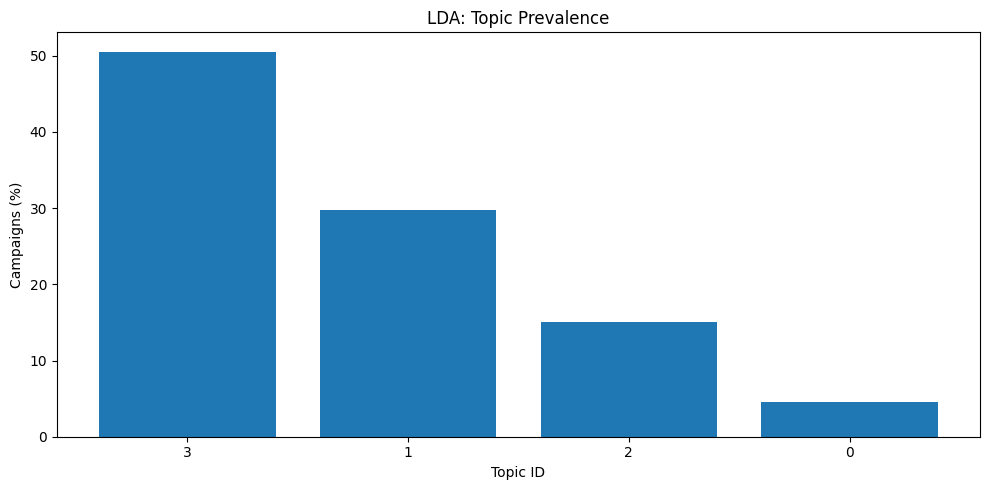

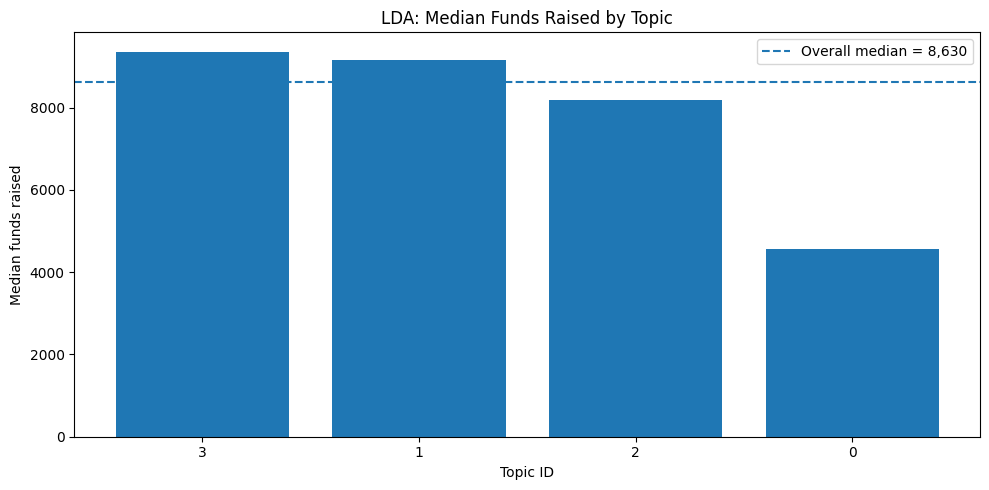

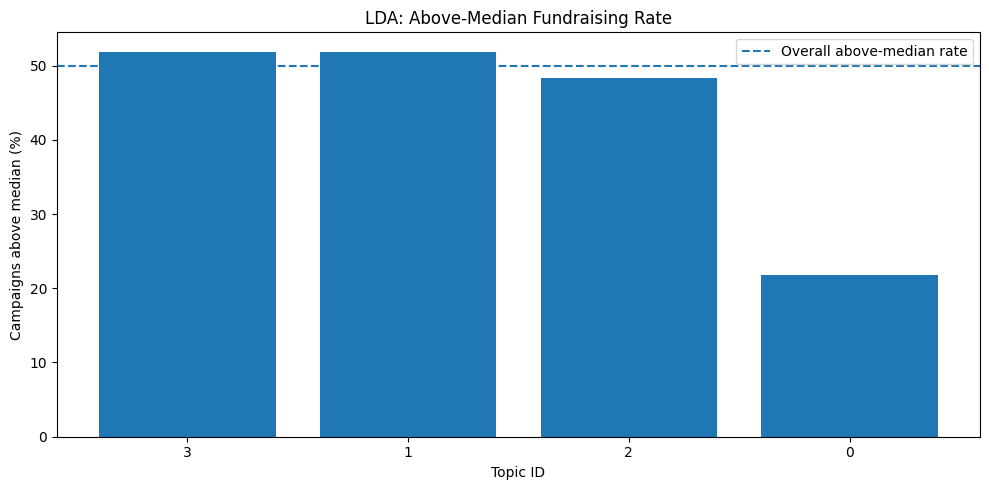

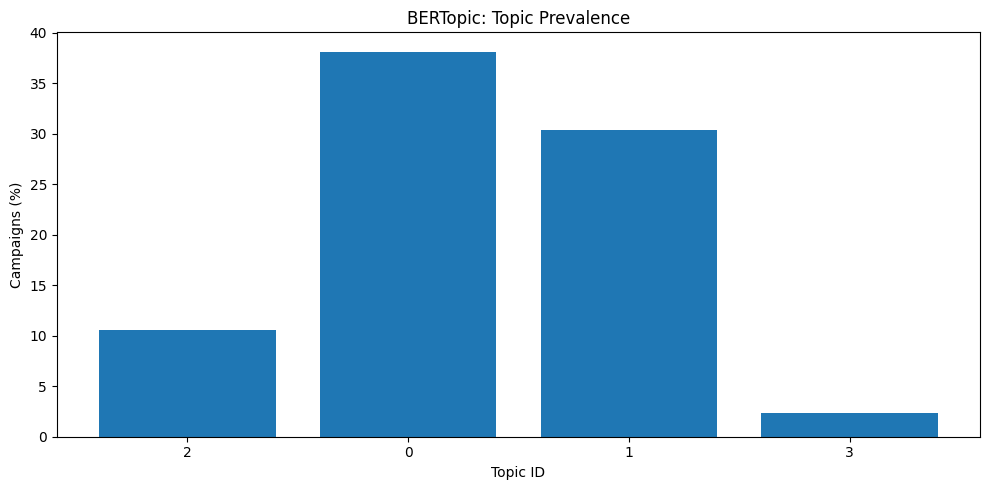

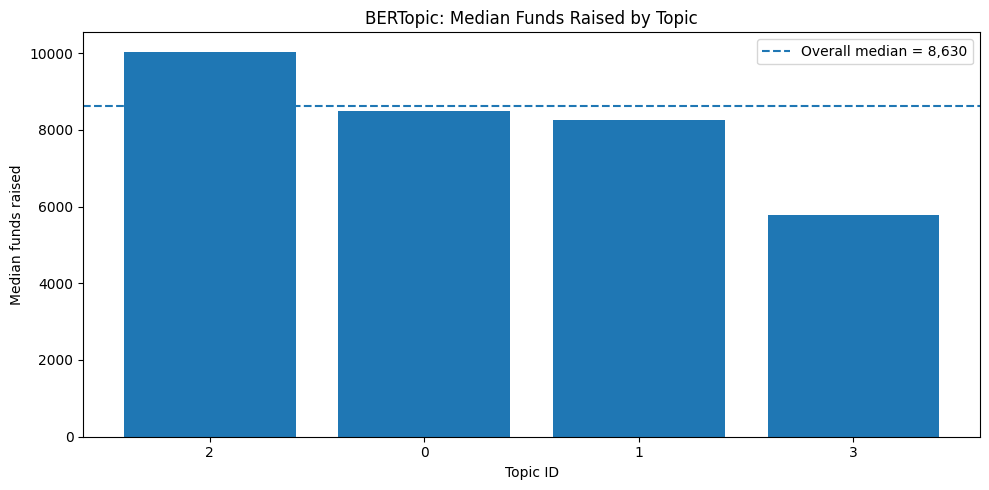

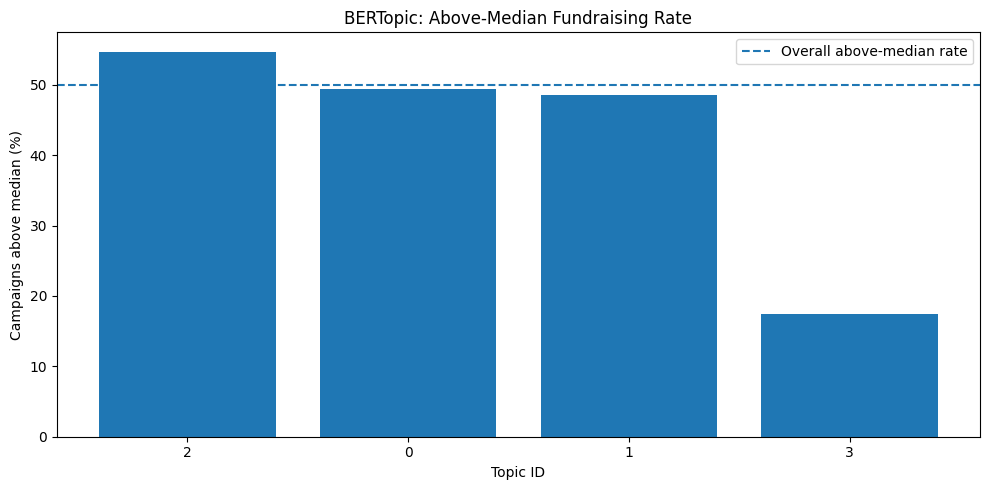

Outcome analysis and plots saved.


In [ ]:
# ============================================================
# TASK D — TOPIC / FUNDRAISING OUTCOME ANALYSIS
# ============================================================

from scipy.stats import kruskal, chi2_contingency, spearmanr
from statsmodels.stats.multitest import multipletests

# ------------------------------------------------------------
# 1. SUMMARIZE TOPIC OUTCOMES
# ------------------------------------------------------------

def summarize_topics(
    data,
    topic_column,
    method_name,
    include_outliers=True
):
    records = []

    for topic_id, group in data.groupby(
        topic_column,
        dropna=False
    ):
        if (
            not include_outliers
            and topic_id == -1
        ):
            continue

        records.append({
            "method": method_name,
            "topic_id": int(topic_id),
            "campaign_count": len(group),
            "topic_prevalence_pct": (
                len(group) / len(data) * 100
            ),
            "median_raised": group["raised"].median(),
            "mean_raised": group["raised"].mean(),
            "mean_raised_log1p": np.log1p(
                group["raised"]
            ).mean(),
            "above_median_count": int(
                group["binary"].sum()
            ),
            "above_median_rate_pct": (
                group["binary"].mean() * 100
            )
        })

    result = pd.DataFrame(records)

    result["median_difference_from_overall"] = (
        result["median_raised"]
        - data["raised"].median()
    )

    result["rate_difference_from_overall_pp"] = (
        result["above_median_rate_pct"]
        - data["binary"].mean() * 100
    )

    return result.sort_values(
        "median_raised",
        ascending=False
    )


lda_summary = summarize_topics(
    df,
    "lda_topic",
    "LDA"
)

bertopic_summary = summarize_topics(
    df,
    "bertopic_topic",
    "BERTopic"
)

print("LDA fundraising outcomes:")
display(lda_summary)

print("BERTopic fundraising outcomes:")
display(bertopic_summary)

lda_summary.to_csv(
    os.path.join(
        OUTPUT_DIR,
        "lda_topic_outcome_summary.csv"
    ),
    index=False
)

bertopic_summary.to_csv(
    os.path.join(
        OUTPUT_DIR,
        "bertopic_topic_outcome_summary.csv"
    ),
    index=False
)

# ------------------------------------------------------------
# 2. KRUSKAL-WALLIS TEST
# ------------------------------------------------------------
# Tests whether fundraising distributions differ across topics.
# The test does not establish causality.

def run_kruskal(data, topic_column, method_name):
    groups = [
        group["raised"].to_numpy()
        for topic_id, group in data.groupby(topic_column)
        if len(group) >= 2
        and not (topic_column == "bertopic_topic"
                 and topic_id == -1)
    ]

    if len(groups) < 2:
        return {
            "method": method_name,
            "test": "Kruskal-Wallis",
            "statistic": np.nan,
            "p_value": np.nan,
            "groups_tested": len(groups)
        }

    statistic, p_value = kruskal(*groups)

    return {
        "method": method_name,
        "test": "Kruskal-Wallis",
        "statistic": statistic,
        "p_value": p_value,
        "groups_tested": len(groups)
    }


# ------------------------------------------------------------
# 3. CHI-SQUARE TEST
# ------------------------------------------------------------
# Tests whether topic membership and binary outcome are associated.

def run_chi_square(data, topic_column, method_name):
    contingency = pd.crosstab(
        data[topic_column],
        data["binary"]
    )

    if (
        topic_column == "bertopic_topic"
        and -1 in contingency.index
    ):
        contingency = contingency.drop(index=-1)

    if contingency.shape[0] < 2 or contingency.shape[1] < 2:
        return {
            "method": method_name,
            "test": "Chi-square",
            "statistic": np.nan,
            "p_value": np.nan,
            "groups_tested": contingency.shape[0]
        }

    statistic, p_value, _, _ = chi2_contingency(
        contingency
    )

    return {
        "method": method_name,
        "test": "Chi-square",
        "statistic": statistic,
        "p_value": p_value,
        "groups_tested": contingency.shape[0]
    }


# ------------------------------------------------------------
# 4. SPEARMAN CORRELATION
# ------------------------------------------------------------
# Uses topic-specific median fundraising and topic prevalence.
# This is descriptive: topic-level observations are not
# independent campaign-level causal evidence.

def run_spearman(summary, method_name):
    usable = summary[
        summary["topic_id"] != -1
    ].dropna(
        subset=[
            "median_raised",
            "topic_prevalence_pct"
        ]
    )

    if len(usable) < 3:
        return {
            "method": method_name,
            "test": "Spearman topic prevalence vs median raised",
            "statistic": np.nan,
            "p_value": np.nan,
            "groups_tested": len(usable)
        }

    statistic, p_value = spearmanr(
        usable["topic_prevalence_pct"],
        usable["median_raised"]
    )

    return {
        "method": method_name,
        "test": "Spearman topic prevalence vs median raised",
        "statistic": statistic,
        "p_value": p_value,
        "groups_tested": len(usable)
    }


test_results = pd.DataFrame([
    run_kruskal(df, "lda_topic", "LDA"),
    run_kruskal(df, "bertopic_topic", "BERTopic"),
    run_chi_square(df, "lda_topic", "LDA"),
    run_chi_square(df, "bertopic_topic", "BERTopic"),
    run_spearman(lda_summary, "LDA"),
    run_spearman(bertopic_summary, "BERTopic")
])

# Adjust p-values across the six reported tests.
valid = test_results["p_value"].notna()

test_results["p_value_holm"] = np.nan

if valid.sum() > 0:
    test_results.loc[
        valid, "p_value_holm"
    ] = multipletests(
        test_results.loc[
            valid, "p_value"
        ],
        method="holm"
    )[1]

test_results["significant_at_0_05_holm"] = (
    test_results["p_value_holm"] < 0.05
)

print("Statistical tests:")
display(test_results)

test_results.to_csv(
    os.path.join(
        OUTPUT_DIR,
        "task_d_statistical_tests.csv"
    ),
    index=False
)

# ------------------------------------------------------------
# 5. CREATE VISUALIZATIONS
# ------------------------------------------------------------

def save_topic_plots(summary, method_name):
    summary = summary.copy()

    # Exclude outlier group from named-topic plots.
    if "topic_id" in summary.columns:
        summary = summary[
            summary["topic_id"] != -1
        ]

    if summary.empty:
        print(f"No regular topics to plot for {method_name}.")
        return

    # Topic prevalence
    plt.figure(figsize=(10, 5))

    plt.bar(
        summary["topic_id"].astype(str),
        summary["topic_prevalence_pct"]
    )

    plt.xlabel("Topic ID")
    plt.ylabel("Campaigns (%)")
    plt.title(f"{method_name}: Topic Prevalence")
    plt.tight_layout()

    plt.savefig(
        os.path.join(
            OUTPUT_DIR,
            f"{method_name.lower()}_topic_prevalence.png"
        ),
        dpi=200
    )

    plt.show()

    # Median funds raised
    plt.figure(figsize=(10, 5))

    plt.bar(
        summary["topic_id"].astype(str),
        summary["median_raised"]
    )

    plt.axhline(
        median_raised,
        linestyle="--",
        label=f"Overall median = {median_raised:,.0f}"
    )

    plt.xlabel("Topic ID")
    plt.ylabel("Median funds raised")
    plt.title(f"{method_name}: Median Funds Raised by Topic")
    plt.legend()
    plt.tight_layout()

    plt.savefig(
        os.path.join(
            OUTPUT_DIR,
            f"{method_name.lower()}_median_raised_by_topic.png"
        ),
        dpi=200
    )

    plt.show()

    # Percentage above the Task B median
    plt.figure(figsize=(10, 5))

    plt.bar(
        summary["topic_id"].astype(str),
        summary["above_median_rate_pct"]
    )

    plt.axhline(
        df["binary"].mean() * 100,
        linestyle="--",
        label="Overall above-median rate"
    )

    plt.xlabel("Topic ID")
    plt.ylabel("Campaigns above median (%)")
    plt.title(
        f"{method_name}: Above-Median Fundraising Rate"
    )

    plt.legend()
    plt.tight_layout()

    plt.savefig(
        os.path.join(
            OUTPUT_DIR,
            f"{method_name.lower()}_above_median_rate.png"
        ),
        dpi=200
    )

    plt.show()


save_topic_plots(lda_summary, "LDA")
save_topic_plots(bertopic_summary, "BERTopic")

print("Outcome analysis and plots saved.")

## 1. Which Method Produces More Interpretable and Useful Topics?

I compared LDA and BERTopic using the coherence of their keywords, the consistency of representative campaigns, the separation between topics, dataset coverage, and their usefulness for understanding fundraising patterns. The goal is not simply to identify the model with the most topics, but to determine which model produces themes that can be interpreted and used responsibly.

### Comparison of LDA and BERTopic

| Criterion | LDA | BERTopic |
|---|---|---|
| Topic structure | Produces four topics that cover all 999 campaigns. | Produces four regular topics and an additional outlier group (Topic -1). |
| Keyword interpretability | The recurring terms are relatively easy to connect to medical support, cancer treatment, hospital care, and family emergencies. | The terms capture broader semantic groupings, including a distinct pet/veterinary-care cluster. |
| Representative campaigns | Examples generally support broad medical and family-support themes, although some topics overlap. | Examples help reveal semantic groupings, but the outlier group is heterogeneous and some regular topics are broad. |
| Topic separation | Several topics share terms such as “help,” “family,” “medical,” and “hospital,” so their boundaries are not always sharp. | The pet-related topic is comparatively distinct; the other medical topics still overlap. |
| Dataset coverage | Every campaign receives one dominant topic. | 186 campaigns (18.62%) are placed in Topic -1 and are not assigned to a regular semantic cluster. |

### Interpretation

LDA produces four broad themes. Topic 0 is associated with general medical and hospital support; Topic 1 emphasizes cancer treatment and medical expenses; Topic 2 reflects hospital care and surgical recovery; and Topic 3 captures family medical emergencies and recovery. These labels summarize the most prominent words and representative campaign examples rather than defining mutually exclusive types of medical need.

The main strength of LDA is its straightforward structure: every campaign is assigned to one of four topics, making it possible to summarize the full dataset. Its main limitation is overlap. Terms such as “help,” “family,” “medical,” and “hospital” appear across several topics, suggesting that some campaigns share multiple themes and that the topic boundaries should not be interpreted too rigidly.

BERTopic identifies related medical and family-support themes, but it also produces a small, more distinct cluster characterized by words such as “dog” and “animal.” The representative campaigns in this cluster include requests for veterinary treatment and pet surgery, so it is reasonably interpreted as veterinary care and pet medical expenses. This is a useful distinction that is less apparent in the broad LDA themes.

BERTopic also assigns 186 campaigns (18.62%) to Topic -1. This is an outlier or unassigned category, not a coherent topic in its own right. Its presence means that BERTopic does not provide a regular thematic label for every campaign. In addition, the veterinary topic contains only 23 campaigns, so its topic-level fundraising estimates are less stable than those for larger groups.

Overall, LDA is the more practical primary model for summarizing the full set of campaigns because it assigns every campaign to a topic and provides relatively accessible broad themes. BERTopic is valuable as a complementary method because it can identify semantic groupings that differ from the LDA structure, including a distinct pet-care cluster. Neither model should be treated as producing perfectly separated or definitive campaign categories.

In [ ]:
# ============================================================
# TASK D — TOPIC INTERPRETABILITY COMPARISON
# ============================================================

# Human-assigned LDA topic names
LDA_TOPIC_NAMES = {
    0: "General Medical and Hospital Support",
    1: "Cancer Treatment and Medical Expenses",
    2: "Hospital Care and Surgical Recovery",
    3: "Family Medical Emergencies and Recovery",
}

# Human-assigned BERTopic topic names
BERTOPIC_TOPIC_NAMES = {
    -1: "Unassigned Campaigns (Outliers)",
    0: "Hospital Care and Family Medical Support",
    1: "Cancer Diagnosis and Treatment Support",
    2: "Family Support During Medical Hardship",
    3: "Veterinary Care and Pet Medical Expenses",
}


# ------------------------------------------------------------
# 1. APPLY THE HUMAN-INTERPRETED NAMES
# ------------------------------------------------------------

df["lda_topic_name"] = df["lda_topic"].map(
    LDA_TOPIC_NAMES
)

df["bertopic_topic_name"] = df["bertopic_topic"].map(
    BERTOPIC_TOPIC_NAMES
)

df.loc[
    df["bertopic_topic"] == -1,
    "bertopic_topic_name"
] = "Unassigned outlier"

# ------------------------------------------------------------
# 2. COMPARE THE METHODS USING EXPLICIT CRITERIA
# ------------------------------------------------------------

lda_outlier_pct = 0.0

bertopic_outlier_pct = (
    df["bertopic_topic"].eq(-1).mean() * 100
)

comparison = pd.DataFrame([
    {
        "Method": "LDA",
        "Number of regular topics": int(
            df["lda_topic"].nunique()
        ),
        "Outlier percentage": lda_outlier_pct,
        "Topic naming approach": (
            "Interpret top words and high-probability examples"
        ),
        "Evaluation criteria": (
            "Word coherence, example consistency, distinctness, "
            "and usefulness for campaign decisions"
        )
    },
    {
        "Method": "BERTopic",
        "Number of regular topics": int(
            df.loc[
                df["bertopic_topic"] != -1,
                "bertopic_topic"
            ].nunique()
        ),
        "Outlier percentage": bertopic_outlier_pct,
        "Topic naming approach": (
            "Interpret c-TF-IDF words and representative examples"
        ),
        "Evaluation criteria": (
            "Semantic consistency, distinctness, example quality, "
            "and usefulness for campaign decisions"
        )
    }
])

display(comparison)

comparison.to_csv(
    os.path.join(
        OUTPUT_DIR,
        "task_d_method_comparison.csv"
    ),
    index=False
)

# ------------------------------------------------------------
# 3. EXPORT NAMED TOPIC SUMMARIES
# ------------------------------------------------------------

lda_summary_named = lda_summary.copy()

lda_summary_named["topic_name"] = (
    lda_summary_named["topic_id"].map(
        LDA_TOPIC_NAMES
    )
)

bertopic_summary_named = bertopic_summary.copy()

bertopic_summary_named["topic_name"] = (
    bertopic_summary_named["topic_id"].map(
        BERTOPIC_TOPIC_NAMES
    )
)

bertopic_summary_named.loc[
    bertopic_summary_named["topic_id"] == -1,
    "topic_name"
] = "Unassigned outlier"

lda_summary_named.to_csv(
    os.path.join(
        OUTPUT_DIR,
        "lda_named_topic_outcomes.csv"
    ),
    index=False
)

bertopic_summary_named.to_csv(
    os.path.join(
        OUTPUT_DIR,
        "bertopic_named_topic_outcomes.csv"
    ),
    index=False
)

# ------------------------------------------------------------
# 4. GENERATE EVIDENCE-BASED RECOMMENDATION TABLE
# ------------------------------------------------------------

def recommendation_evidence(summary, method_name):
    regular = summary[
        summary["topic_id"] != -1
    ].copy()

    regular = regular.dropna(
        subset=[
            "median_raised",
            "above_median_rate_pct"
        ]
    )

    if regular.empty:
        return pd.DataFrame()

    overall_rate = df["binary"].mean() * 100
    overall_median = df["raised"].median()

    regular["method"] = method_name

    regular["median_vs_overall"] = np.where(
        regular["median_raised"] > overall_median,
        "Above overall median",
        np.where(
            regular["median_raised"] < overall_median,
            "Below overall median",
            "Equal to overall median"
        )
    )

    regular["above_median_rate_vs_overall"] = np.where(
        regular["above_median_rate_pct"] > overall_rate,
        "Higher than overall rate",
        np.where(
            regular["above_median_rate_pct"] < overall_rate,
            "Lower than overall rate",
            "Equal to overall rate"
        )
    )

    return regular


recommendations = pd.concat(
    [
        recommendation_evidence(
            lda_summary_named, "LDA"
        ),
        recommendation_evidence(
            bertopic_summary_named, "BERTopic"
        )
    ],
    ignore_index=True
)

recommendations.to_csv(
    os.path.join(
        OUTPUT_DIR,
        "task_d_recommendation_evidence.csv"
    ),
    index=False
)

print("Evidence table for managerial recommendations:")
display(recommendations)

print(
    "\nInterpretation reminder: these findings identify "
    "associations in the observed campaigns. They do not "
    "show that emphasizing a topic will cause more donations."
)

,Method,Number of regular topics,Outlier percentage,Topic naming approach,Evaluation criteria
0,LDA,4,0.000000,Interpret top words and high-probability examples,"Word coherence, example consistency, distinctn..."
1,BERTopic,4,18.618619,Interpret c-TF-IDF words and representative ex...,"Semantic consistency, distinctness, example qu..."


Evidence table for managerial recommendations:


,method,topic_id,campaign_count,topic_prevalence_pct,median_raised,mean_raised,mean_raised_log1p,above_median_count,above_median_rate_pct,median_difference_from_overall,rate_difference_from_overall_pp,topic_name,median_vs_overall,above_median_rate_vs_overall
0,LDA,3,505,50.550551,9360.0,14661.695050,9.189612,262,51.881188,730.0,1.931238,Family Medical Emergencies and Recovery,Above overall median,Higher than overall rate
1,LDA,1,297,29.729730,9160.0,12430.030303,9.110421,154,51.851852,530.0,1.901902,Cancer Treatment and Medical Expenses,Above overall median,Higher than overall rate
2,LDA,2,151,15.115115,8186.0,11939.801325,9.013205,73,48.344371,-444.0,-1.605579,Hospital Care and Surgical Recovery,Below overall median,Lower than overall rate
3,LDA,0,46,4.604605,4559.0,7396.500000,8.447361,10,21.739130,-4071.0,-28.210820,General Medical and Hospital Support,Below overall median,Lower than overall rate
4,BERTopic,2,106,10.610611,10039.5,14743.000000,9.257056,58,54.716981,1409.5,4.767031,Family Support During Medical Hardship,Above overall median,Higher than overall rate
5,BERTopic,0,381,38.138138,8500.0,13629.740157,9.080022,188,49.343832,-130.0,-0.606118,Hospital Care and Family Medical Support,Below overall median,Lower than overall rate
6,BERTopic,1,303,30.330330,8263.0,12296.986799,9.071846,147,48.514851,-367.0,-1.435098,Cancer Diagnosis and Treatment Support,Below overall median,Lower than overall rate
7,BERTopic,3,23,2.302302,5770.0,6975.304348,8.563457,4,17.391304,-2860.0,-32.558646,Veterinary Care and Pet Medical Expenses,Below overall median,Lower than overall rate



Interpretation reminder: these findings identify associations in the observed campaigns. They do not show that emphasizing a topic will cause more donations.


# Task D: Topic Modeling Interpretation and Fundraising Analysis

## 2. Analysis of Topics and Fundraising Outcomes

### Methodology

After fitting the topic models using campaign text, I examined whether fundraising outcomes varied across the resulting topics. Fundraising outcomes were not used to create the topics; they were joined to the topic assignments afterward for evaluation. This separation helps avoid defining topics directly from the outcome being analyzed.

I used three descriptive measures:

1. **Topic prevalence:** The number and percentage of campaigns assigned to each topic.
2. **Median funds raised:** The median amount raised by campaigns in the topic. The median is less sensitive to unusually large campaigns than the mean.
3. **Above-median fundraising rate:** The percentage of campaigns in the topic that raised more than the overall dataset median of **$8,630**.

I also used two statistical tests. The Kruskal–Wallis test evaluates whether the distribution of amounts raised differs across topic groups. The chi-square test evaluates whether the proportion of campaigns above the overall median differs across topics. Holm-adjusted p-values are used for the reported significance decisions.

These tests identify group-level associations. They do not establish that a topic causes a campaign to raise more or less money, and an omnibus significant result does not show that every pair of topics differs significantly.

### 2.1 LDA Fundraising Outcomes

| LDA topic | Campaigns | Prevalence | Median raised | Above-median rate |
|---|---:|---:|---:|---:|
| Topic 3: Family Medical Emergencies and Recovery | 505 | 50.55% | $9,360.00 | 51.88% |
| Topic 1: Cancer Treatment and Medical Expenses | 297 | 29.73% | $9,160.00 | 51.85% |
| Topic 2: Hospital Care and Surgical Recovery | 151 | 15.12% | $8,186.00 | 48.34% |
| Topic 0: General Medical and Hospital Support | 46 | 4.60% | $4,559.00 | 21.74% |

*Topic labels are human interpretations of the top words and representative campaign examples.*

### Interpretation of LDA Results

Topic 3 is the largest LDA group, containing 505 campaigns (50.55%). It has a median of $9,360, which is $730 above the overall median, and 51.88% of its campaigns exceed the overall median. Topic 1 has a similar above-median rate of 51.85% and a median of $9,160. The two largest groups therefore show broadly similar fundraising outcomes in this sample.

Topic 2 contains 151 campaigns and has a median of $8,186, slightly below the overall median. Its above-median rate is 48.34%, also close to the overall benchmark.

Topic 0 has the lowest observed median, $4,559, and the lowest above-median rate, 21.74%. However, it contains only 46 campaigns, substantially fewer than the other LDA topics. Its lower results are worth investigating, but the smaller group size means they should be interpreted cautiously.

Taken together, the LDA results suggest that fundraising outcomes are not uniform across the four assigned topics. The differences are driven in part by Topic 0, while the two largest topics have quite similar above-median rates. The results do not imply that campaigns belonging to a particular theme will necessarily achieve a particular fundraising outcome.

### 2.2 BERTopic Fundraising Outcomes

| BERTopic group | Campaigns | Prevalence | Median raised | Above-median rate |
|---|---:|---:|---:|---:|
| Topic -1: Outlier / Unassigned Campaigns | 186 | 18.62% | $10,043.50 | 54.84% |
| Topic 2: Family Support During Medical Hardship | 106 | 10.61% | $10,039.50 | 54.72% |
| Topic 0: Hospital Care and Family Medical Support | 381 | 38.14% | $8,500.00 | 49.34% |
| Topic 1: Cancer Diagnosis and Treatment Support | 303 | 30.33% | $8,263.00 | 48.51% |
| Topic 3: Veterinary Care and Pet Medical Expenses | 23 | 2.30% | $5,770.00 | 17.39% |

*Topic -1 is BERTopic's outlier/unassigned group. It is included in the descriptive table to account for all campaigns, but it should not be interpreted as one coherent theme.*

### Interpretation of BERTopic Results

Among the regular BERTopic topics, Topic 2 has the highest median fundraising amount ($10,039.50) and the highest above-median rate (54.72%). Its 106 campaigns are associated with family support during medical hardship. The outlier group has very similar observed values, with a median of $10,043.50 and an above-median rate of 54.84%. However, because Topic -1 combines campaigns that the model did not confidently place in a regular cluster, its results cannot be attributed to one shared campaign theme.

Topic 0 is the largest regular topic, with 381 campaigns (38.14%). Its median is $8,500, slightly below the overall median, and 49.34% of campaigns exceed the overall median. Topic 1 contains 303 campaigns and has a median of $8,263, with an above-median rate of 48.51%. These two larger groups have relatively similar outcome rates.

Topic 3, the veterinary-care and pet-medical-expenses cluster, contains only 23 campaigns. It has a median of $5,770 and an above-median rate of 17.39%. This is the lowest observed rate among the BERTopic groups, but the small sample size makes the estimate uncertain. It should not be generalized to all veterinary or animal-related fundraisers.

BERTopic therefore reveals a potentially distinct pet-care theme, while the medical topics have relatively similar fundraising rates. Its outlier group also illustrates an important limitation: a substantial share of campaigns cannot be summarized by the regular topic labels.

### 2.3 Statistical Evidence

| Method | Test | Test statistic | Holm-adjusted p-value | Significant at 0.05? |
|---|---|---:|---:|---|
| LDA | Kruskal–Wallis: funds raised across topics | 27.332 | 0.000025 | Yes |
| BERTopic | Kruskal–Wallis: funds raised across regular topics | 11.815 | 0.024132 | Yes |
| LDA | Chi-square: topic vs. above-median outcome | 15.982 | 0.004574 | Yes |
| BERTopic | Chi-square: topic vs. above-median outcome | 10.621 | 0.027928 | Yes |

Both methods show statistically significant differences in fundraising outcomes across topic groups at the 0.05 level after Holm adjustment. For LDA, the Kruskal–Wallis result indicates that the distribution of amounts raised differs across the four topics. The chi-square result also indicates that above-median fundraising rates are not the same across the four topics.

The corresponding BERTopic tests are also significant. For these tests, Topic -1 is excluded from the semantic topic comparison because it is an unassigned outlier group; the descriptive table above still reports it separately. The results indicate that fundraising outcomes vary across the regular BERTopic clusters, although the small size of Topic 3 calls for caution.

The LDA p-values are smaller in this run, which is stronger statistical evidence against equal outcomes under the tested grouping. This does not, by itself, mean LDA is a better predictive model or that its topic differences are larger in practical terms. The tests are omnibus comparisons and do not identify which specific pairs of topics differ; pairwise post-hoc testing would be needed for that.

The analysis also reports a Spearman relationship between topic prevalence and median funds raised. For LDA, the four topic-level points happen to show a perfect positive rank ordering in this run; however, this calculation is based on only four aggregated observations and should be treated as exploratory rather than strong evidence. For BERTopic, the relationship is not statistically significant (Spearman ρ = 0.40, p = 0.60). Overall, the analysis does not provide a reliable basis for concluding that more common themes consistently raise more money.

### Overall Interpretation

The two models produce different but complementary views of the campaigns. LDA offers a complete, relatively simple partition of the dataset, while BERTopic identifies a distinct veterinary-care cluster and leaves 18.62% of campaigns unassigned. In both models, topic groups differ in their observed fundraising outcomes, but the size and composition of individual groups matter when interpreting those differences.

The most important practical finding is not that one topic guarantees higher fundraising. Rather, topic membership can help organize campaigns into groups for further review. The differences observed here can guide questions about campaign communication, audience reach, fundraising goals, and campaign exposure, which would need to be examined separately.

## 3. Recommendations for Future Fundraising Campaigns

### Recommendation 1: Examine successful campaigns within the stronger-performing themes

The LDA cancer-treatment and family-medical-emergency topics have above-median fundraising rates of approximately 52%. In BERTopic, the family-support-during-medical-hardship cluster has an above-median rate of 54.72%. These results make the corresponding campaigns useful candidates for closer qualitative review.

The organization could examine how these campaigns explain the medical situation, describe the intended use of funds, communicate urgency, and provide updates to donors. The purpose would be to identify recurring communication practices that may be worth testing, not to assume that the topic itself explains the fundraising outcome.

### Recommendation 2: Investigate campaigns with lower observed outcomes

LDA Topic 0 and BERTopic Topic 3 have notably lower median fundraising amounts and above-median rates than the other groups. These results should be treated as signals for further investigation, not as evidence that general medical-support or veterinary campaigns are inherently less successful.

A useful next step would be to review individual campaigns and compare factors such as the clarity of the fundraising goal, the specificity of the requested expenses, campaign reach, update frequency, social-network size, and time available to collect donations. This could help distinguish differences in campaign execution from differences in the circumstances faced by campaign organizers.

### Recommendation 3: Use topic assignments as an analytical aid, not a resource-allocation rule

Topic-level statistics describe groups and do not predict every individual campaign. There are successful campaigns in groups with lower median outcomes and less successful campaigns in groups with higher median outcomes.

The organization should therefore avoid deprioritizing campaigns solely because of their topic assignment. Topic labels can support campaign review, segmentation, and the selection of comparable campaigns, but individual circumstances and campaign-level information should remain part of any decision.

### Recommendation 4: Test messaging changes through controlled experiments

The topic analysis can generate hypotheses for future experiments. For example, within comparable medical campaigns, the organization could test a message that itemizes the intended medical expenses against a more general request for support. Other tests could examine how the campaign explains urgency, communicates progress, or structures updates.

Where feasible, visitors or comparable campaigns should be randomly assigned to messaging variants. Outcomes could include donation conversion rate, average donation, donations per visitor, and funds raised over the same observation period. A controlled design would provide stronger evidence about whether a specific communication change improves fundraising performance.

### Limitations and Interpretation

This analysis is observational. It identifies associations between text-derived topic assignments and recorded fundraising amounts, but it does not isolate the causal effect of a campaign theme.

Several factors could influence the observed differences, including the severity and type of medical need, fundraising target, donor network, campaign visibility, and campaign duration. The available data also do not provide reliable donation timestamps or consistent campaign exposure/closure periods. As a result, campaigns may have had different amounts of time to accumulate donations, and recorded totals should not be interpreted as directly comparable fundraising rates over equal exposure periods.

The text used for topic modeling combines campaign descriptions with image-derived captions. The image captions can include generic descriptions of people, settings, or objects, rather than only information about the medical need. Consequently, some topic assignments may reflect visual-caption language as well as the campaign narrative. The topics should be interpreted as themes in the combined text representation, not as a perfect classification of campaign purpose.

BERTopic's outlier group and the small size of some topics also limit interpretation. In particular, the 23-campaign veterinary topic provides a small basis for estimating typical fundraising outcomes. Similarly, LDA topics are broad and overlapping, so the human-assigned labels are summaries rather than strict categories.

For these reasons, the findings should be treated as **descriptive associations, not causal effects**. They are useful for identifying campaign groups and generating hypotheses, but they cannot establish that changing a campaign's topic or wording will necessarily increase donations.

## Conclusion

LDA provides a practical overview of all 999 campaigns through four broad, interpretable topics. BERTopic offers a complementary semantic view, including a distinct pet-care cluster, but leaves 18.62% of campaigns in its outlier group. Both methods show statistically significant variation in fundraising outcomes across their topic groupings in this run.

The strongest use of these results is to guide further investigation: review campaigns within stronger- and weaker-performing groups, examine campaign-level factors that may explain differences, and test specific messaging practices through controlled experiments. Topic modeling helps organize the evidence and generate useful hypotheses; it does not establish which campaign characteristics cause fundraising success.